# Catalunya2 — raceline optimisation with the OCP-extracted G-G-V

This notebook uses the **Catalunya2 circuit and the extracted G-G-V envelope**
shared by the Trento group, so that every OptiLine method is run against **the
same performance envelope the minimum-lap-time OCP (MLT-DT) used**.

Every file the notebook reads is kept verbatim in **`input_files/`**:

| file | what it is |
|---|---|
| `Catalunya.txt` | 2-D track: `abscissa`, `curvature`, mid-line, half-widths |
| `mlt_dt_sol_selected.csv` | their double-track minimum-lap-time solution (MLT-DT) |
| `mlts_pm_solution.csv` | their point-mass minimum-lap-time solution |
| `ggv_sportcar.json` | the extracted g-g-v envelope |
| `vehicle_2/vehicle.json` | vehicle data (width, speed limits, acceleration lags) |

Contents:
1. Helpers (G-G-V loading, fast interpolators, track/profile utilities)
2. Load the map + G-G-V; plot the circuit
3. References: MLT-DT and point-mass solutions, and `fb2d` reproduction of each
4. SP, MC, Bilevel (ZO/CMA), Blackbox (ZO/CMA) — with the shared G-G-V
5. Lap-time table, velocity profiles, racelines

<!-- **Note on the length scales.** The shared files carry two incompatible length
signals. `zeta` (identical to the road file's `abscissa`, and the OCP's independent
spatial coordinate) totals 4721.67 m, while the polyline through the tabulated
mid-line it parameterises is 4672.77 m. The 1.05 % difference sits entirely in the
corners — on segments with `|kappa| < 1e-3` the chord matches `d(abscissa)` to
2e-5, on segments with `|kappa| > 5e-3` it is 2.5 % short — and chord-to-arc from
the tabulated `curvature` accounts for only 0.03 m of it. Every OptiLine result is
computed on the Cartesian geometry, so wherever a shared solution is used as a
reference we report **both** its exported lap time and the lap time obtained by
re-integrating its own speed along its own `(x, y)` path. -->

<!-- **Notes.** The shared G-G-V already contains aerodynamic drag, so every velocity
profile here is computed with `drag_coeff = 0` to avoid double-counting.
The G-G-V is consumed exactly as in the shared `main_fbga_solution.py`
(2-D grid for `ax_max/ax_min` over `(v, ay)`, 1-D `ay_max(v)`), but through
OptiLine's `gg_upper / gg_lower / gg_range` interface. -->


In [ ]:
# ===========================================================================
# Imports and configuration
# ===========================================================================
import os, json, time, copy, math, configparser

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams.update({
    "font.family": "serif", "font.size": 9, "axes.labelsize": 9, "axes.titlesize": 9,
    "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
})

import quadprog
from OptiLine import solvers, utils
from OptiLine.KinematicProfs import (
    calc_vel_profile, calc_vel_profile_fb2d, calc_ax_profile, calc_t_profile,
)
from OptiLine.utils import (
    calc_splines, create_raceline, calc_head_curv_an, load_ggv_envelope,
    seg_bounds, subsample_reftrack, raceline_from_alpha, track_borders,
    centreline_frame, project_to_centreline, project_signed, smooth_over,
    ggv_tables_from_envelope,
)

# ---------------------------------------------------------------------------
# Paths
# ---------------------------------------------------------------------------
# Every file this notebook reads lives in input_files/, copied there verbatim from
# the batches shared by the Trento group (latest: 2026-09-08).
IN_DIR    = "input_files"
ROAD_FILE = os.path.join(IN_DIR, "Catalunya.txt")                 # corrected export, 2026-10-08
PM_FILE   = os.path.join(IN_DIR, "mlts_pm_solution.csv")          # point-mass MLT, 2026-10-14
DT_FILE   = os.path.join(IN_DIR, "mlt_dt_sol_selected.csv")       # MLT double-track, 2026-10-14
VEH_FILE  = os.path.join(IN_DIR, "vehicle_2", "vehicle.json")
GGV_FILE  = os.path.join(IN_DIR, "ggv_sportcar.json")             # fitted G-G-V, 2026-10-14

FIG_DIR   = "paper_figs"
os.makedirs(FIG_DIR, exist_ok=True)

CIRCUIT = "Catalunya2"          # the real Catalunya shared by the Trento group

# ---------------------------------------------------------------------------
# Vehicle / discretisation settings for this case
#   - the G-G-V already includes drag  ->  DRAG = 0.0
#   - W_VEH is the full vehicle width (per-side clearance = W_VEH/2)
# ---------------------------------------------------------------------------
VEH2 = dict(
    w_veh       = 1.8,      # vehicle_2 W_total; the point-mass OCP uses the same value
    m_veh       = 1000.0,   # only used together with drag; irrelevant since DRAG=0
    drag_coeff  = 0.0,      # drag already inside the shared G-G-V
    kappa_bound = 0.2,      # curvature bound for the QPs [1/m] (track max |kappa| ~ 0.04)
    fw          = None,        # velocity-profile moving-average window
)

# Interior-point corridor constraints (OptiLine >= 0.2.3). The QPs constrain the
# raceline only at the reference-track nodes; the spline interpolated between them
# bulges outside the track by ~0.11 m at this node spacing. Constraining a few
# interior points per segment removes that at ~8% extra QP time. 
N_INTERP_CON = 4

# How the reference-track nodes are picked out of the track file:
#   'index'    every step-th row, as before. The shared track is sampled at 1.0 m in
#              the corners and 4.0 m on the straights, so at STEP = 8 this gives
#              segments between 7 and 32 m long (ratio 4.6).
#   'seg_unif' nodes at uniform ARC LENGTH, interpolated from the track rows. Short
#              segments next to long ones make the cubic spline curl sharply, which
#              corrupts the curvature and hence the velocity profile, so this is the
#              safer default on a non-uniformly sampled track.
# Either way the node COUNT is round(n_rows / STEP), so STEP keeps its meaning.
SUBSAMPLE = 'seg_unif'          # 'seg_unif' or 'index'
# SUBSAMPLE = 'index'          # 'seg_unif' or 'index'

STEP = 12     
SI   = 4.0    
# Raceline interpolation step used for the FINAL, reported velocity profile.


SI_FINAL = 1.0

# ---------------------------------------------------------------------------
# How the shared G-G-V envelope is reconstructed (utils.load_ggv_envelope).
#   'mlts'   : build it with mlts_point_mass.GGVConstr, then sample onto a fast
#              lookup grid. This is the construction the point-mass OCP is itself
#              constrained with, so the comparison is like-for-like.
#   'linear' : bilinear interpolation straight on the tabulated grid. Faithful to
#              the file, but it also reproduces its artefacts -- this envelope is
#              fitted to close at top speed and stores ax_min = 0 there, which
#              removes most of the braking capability over the last few m/s and
#              costs a minimum-curvature lap about 0.5 s.
# The two agree to ~0.01 m/s^2 below 70 m/s; see the validation cell.
# ---------------------------------------------------------------------------
GGV_INTERP = 'mlts'     # 'mlts' or 'linear'

# Only consulted by the vanilla point-mass profiler, vel_profile(mode='fb'); the
# fb2d path uses the full envelope and never reads it.
DYN_MODEL_EXP = 2.0

# ---------------------------------------------------------------------------
# Repeats for the stochastic solvers. ZORM and CMA-ES are unseeded, so the
# blackbox and bilevel rows are the mean over N_REPEATS runs with their sample
# standard deviation. The shared reference solutions are given, not re-solved,
# and the geometric rows are deterministic, so both run once.
# ---------------------------------------------------------------------------
N_REPEATS = 3


def agg(vals):
    """(mean, sample std) of a list of scalars."""
    a = np.asarray(vals, dtype=float)
    return float(a.mean()), (float(a.std(ddof=1)) if a.size > 1 else 0.0)


def median_idx(vals):
    """Index of the median run; the raceline plotted in x-y comes from this run,
    since the pointwise mean of several distinct paths is not itself a path."""
    a = np.asarray(vals, dtype=float)
    return int(np.argsort(a)[(a.size - 1) // 2])

# ---------------------------------------------------------------------------
# Zeroth-order hyper-parameters and iteration budgets.
# ---------------------------------------------------------------------------


#For a quick diagnosis of the G-G-V, you can run for much fewer iterations.

BILEVEL = dict(iterations_ZO=50, iterations_CMA=25, popsize=8,
               mu=1e-6, h=8e-4, t=1, MC=1, sigma=0.0035)
BBA     = dict(iters_ZO=900, iters_CMA=800, popsize=12,
               mu=1e-6, h=9e-4, t=12, sigma=0.003, n_jobs=12)


print("Configuration loaded.")


# Per-segment spline-length bounds for the bilevel optimiser: each interval is
# constrained to [lo * s_i, hi * s_i] of its OWN initial length (OptiLine >= 0.2.0).
# This replaces the previous global box [min_i s_i, k * max_i s_i], where a single
# short segment lowered the bound for every segment and could make the inner QP
# infeasible.
S_SCALE = (0.7, 1.4)  # (lo, hi) scaling factors for each segment's spline length

Configuration loaded.


In [ ]:
# ===========================================================================
# Helper functions
# ===========================================================================

# --- G-G-V ------------------------------------------------------------------
# The envelope plumbing (fast picklable lookups, JSON -> gg_upper/gg_lower/gg_range)
# now lives in OptiLine.utils.load_ggv_envelope, so every notebook and every solver
# reconstructs the envelope the same way. It used to be ~130 lines here.


def read_trento_solution(path):
    '''Read one of the shared solution files and restore the centreline arc length.

    The files tabulate two different length signals, neither of which is the arc
    length of the centreline (xTrj, yTrj) that every OptiLine result is projected
    onto:

      zeta            the OCP's independent spatial coordinate. It is bit-identical
                      to the road file's `abscissa` column and totals 4721.67 m,
                      while the polyline through the mid-line it parameterises is
                      4672.77 m long. The 1.05% is concentrated in the corners
                      (chord/d_abscissa = 0.99998 where |kappa| < 1e-3, 1.025 where
                      |kappa| > 5e-3) and chord-to-arc from the tabulated curvature
                      explains 0.03 m of it.
      travelled_space the distance driven. Cartesian in the MLT-DT export
                      (== cumulative chord of its own x, y) but curvilinear in the
                      point-mass one (4673.18 m against a 4638.16 m Cartesian path),
                      so the two files do not use the same convention.

    Earlier versions of the MLT-DT file carried the centreline arc length in a
    column called `abscissa`; it has since been removed, so we rebuild it here.
    Adds:
      x_traj, y_traj  aliases of the driven trajectory (x, y)
      abscissa        cumulative chord of the centreline (xTrj, yTrj)
      s_driven        cumulative chord of the driven path (x, y)
    '''
    df = pd.read_csv(path, sep="\t", header=0)
    df['x_traj'] = df['x']
    df['y_traj'] = df['y']
    _c = np.hypot(*np.diff(np.column_stack([df['xTrj'].values,
                                            df['yTrj'].values]), axis=0).T)
    df['abscissa'] = np.concatenate([[0.0], np.cumsum(_c)])
    _d = np.hypot(*np.diff(np.column_stack([df['x'].values,
                                            df['y'].values]), axis=0).T)
    df['s_driven'] = np.concatenate([[0.0], np.cumsum(_d)])
    return df


def refine_at_si(alpha, normvec, si=None):
    """Re-evaluate a finished alpha at SI_FINAL; returns (lap, s, vx, rl, kappa, el).

    alpha lives on the reference-track nodes, so this is an exact re-evaluation of
    the same raceline at a finer interpolation step, not a re-optimisation.
    """
    si = SI_FINAL if si is None else si
    rl, kappa, el = raceline_from_alpha(reftrack, normvec, alpha, stepsize_interp=si)
    vx = vel_profile(kappa, el, mode='fb2d', filt_window=VEH2['fw'])
    return laptime_closed(vx, el), arc_length(el), vx, rl, kappa, el


def laptime_on_path(df):
    '''Re-integrate a shared solution's own speed along its own (x, y) path.

    dt = 2*ds/(v_i + v_i+1) is exact for piecewise-constant acceleration between
    samples, so the only thing that changes relative to the exported `time` column
    is the length scale: this is the lap time the same solution would have on the
    Cartesian geometry that every OptiLine result uses.
    '''
    _v = df['V'].values
    _ds = np.diff(df['s_driven'].values)
    return float(np.sum(2.0 * _ds / (_v[:-1] + _v[1:])))


# --- track ------------------------------------------------------------------
def read_shared_solution(path, accel_in_g=False):
    '''Read a shared Trento solution (point-mass or double-track).

    Same as read_pm_solution, plus `accel_in_g`: the MLT-DT export gives ax/ay in g
    while the point-mass export gives them in m/s^2, despite identical column names.
    Verified against the geometry, where a_y must equal V^2 * kappa_trj.
    '''
    df = read_pm_solution(path)
    if accel_in_g:
        df['ax'] = df['ax'].values * 9.81
        df['ay'] = df['ay'].values * 9.81
    return df


def read_pm_solution(path):
    '''Read the shared point-mass OCP solution.

    Schema (2026-10-08 export): abscissa is the centreline curvilinear coordinate and
    is now genuinely the arc length of the mid-line, distance is the driven Cartesian
    path, x_trj/y_trj the trajectory and x_mid_line/y_mid_line the centreline. The
    reported `time` and the time implied by (x_trj, y_trj) agree to 0.0003 %, so there
    is no longer a length-scale ambiguity to carry around.

    Adds the aliases the rest of this notebook expects:
      x_traj, y_traj  the driven trajectory
      s_driven        the driven Cartesian path length (== the `distance` column)
      kappa_path      curvature of the driven line; for a point mass a_y = V^2 kappa
    '''
    df = pd.read_csv(path)
    df['x_traj'] = df['x_trj']
    df['y_traj'] = df['y_trj']
    df['s_driven'] = df['distance']
    df['kappa_path'] = df['ay'].values / df['V'].values ** 2
    return df


def load_catalunya2(road_df, step=STEP, mode=None):
    '''
    OptiLine reference track [x, y, w_right, w_left] from the shared road file.

    The node picking itself is utils.subsample_reftrack; SUBSAMPLE selects 'arc'
    (uniform arc length, the safe default on this non-uniformly sampled track) or
    'index' (every step-th row).
    '''
    full = np.column_stack([road_df['x_mid_line'].values, road_df['y_mid_line'].values,
                            road_df['width_no_kerbs_R'].values,
                            road_df['width_no_kerbs_L'].values])
    ref = subsample_reftrack(full, step=step,
                             mode=('arc' if (mode or SUBSAMPLE) == 'seg_unif'
                                   else (mode or SUBSAMPLE)),
                             abscissa=road_df['abscissa'].values)
    sp = np.median(np.hypot(*np.diff(full[:, :2], axis=0).T))
    if np.hypot(*(full[-1, :2] - full[0, :2])) < 0.5 * sp:
        full = full[:-1]
    return ref, full


def vel_profile(kappa, el, mode='fb2d', filt_window=None):
    '''
    Closed velocity profile for the shared G-G-V.
      mode='fb2d' : FBGA with the shared envelope (gg_upper / gg_lower / gg_range)
      mode='fb'   : vanilla forward-backward with the projected point-mass G-G-V
    Drag is zero in both cases (already contained in the shared envelope).
    '''
    if mode == 'fb2d':
        return calc_vel_profile_fb2d(
            ax_max_machines=AXMACH_TAB, ggv=None, v_max=V_MAX,
            kappa=kappa, el_lengths=el, closed=True,
            drag_coeff=VEH2['drag_coeff'], m_veh=VEH2['m_veh'],
            gg_upper=GG_UPPER, gg_lower=GG_LOWER, gg_range=GG_RANGE,
            filt_window=filt_window)
    elif mode == 'fb':
        return calc_vel_profile(
            ggv=GGV_TAB, ax_max_machines=AXMACH_TAB, v_max=V_MAX,
            kappa=kappa, el_lengths=el, closed=True, filt_window=filt_window,
            dyn_model_exp=DYN_MODEL_EXP, drag_coeff=VEH2['drag_coeff'], m_veh=VEH2['m_veh'])
    raise ValueError(mode)


def laptime_closed(vx, el):
    '''Lap time via OptiLine's calc_t_profile (identical integrator for every method).'''
    vx_cl = np.append(vx, vx[0])
    ax = calc_ax_profile(vx_profile=vx_cl, el_lengths=el, eq_length_output=False)
    return float(calc_t_profile(vx_profile=vx, ax_profile=ax, el_lengths=el)[-1])


def arc_length(el):
    return np.concatenate(([0.0], np.cumsum(el)[:-1]))


# --- geometric solvers ------------------------------------------------------
def solve_mincurv(reftrack):
    '''Minimum-curvature QP -> (alpha, normvectors).'''
    _, _, M, normvec = calc_splines(
        path=np.vstack((reftrack[:, :2], reftrack[0, :2])),
        el_lengths=seg_bounds(reftrack)[2], use_dist_scaling=True)
    alpha, _ = solvers.opt_min_curv(
        reftrack=reftrack, normvectors=normvec, A=M,
        kappa_bound=VEH2['kappa_bound'], w_veh=VEH2['w_veh'],
        print_debug=False, plot_debug=False, closed=True,
        n_interp_con=N_INTERP_CON)
    return alpha, normvec


def solve_shortestpath(reftrack):
    '''
    Shortest-path QP -> (alpha, normvectors).
    We call solvers.OSP + quadprog directly instead of solvers.ShortestPath because
    the latter hard-codes drag_coeff=0.75 / m_veh=1000 in its velocity profile, which
    would double-count the drag already contained in the shared G-G-V.
    '''
    _, _, M, normvec = calc_splines(
        path=np.vstack((reftrack[:, :2], reftrack[0, :2])),
        el_lengths=seg_bounds(reftrack)[2], use_dist_scaling=True)
    # A=M enables the interior-point corridor constraints added in OptiLine 0.2.3:
    # without it only the nodes are constrained and the interpolated spline bulges
    # outside the track between them.
    H, f, G_, h_ = solvers.OSP(reftrack=reftrack, normvectors=normvec,
                               w_veh=VEH2['w_veh'], print_debug=False,
                               A=M, closed=True, n_interp_con=N_INTERP_CON)
    alpha = quadprog.solve_qp(H, -f, -G_.T, -h_, 0)[0]
    return alpha, normvec


# --- optimiser factories ----------------------------------------------------
def build_optct(reftrack, vel_solver='fb2d'):
    '''Bilevel optimiser (Opt_min_CurvTime) wired to the shared G-G-V.'''
    kw = dict(
        reftrack=reftrack, center=reftrack, mu=BILEVEL['mu'], h=BILEVEL['h'],
        kapb=VEH2['kappa_bound'], sfty=VEH2['w_veh'] / 2, si=SI, vm=V_MAX,
        m_veh=VEH2['m_veh'], drag_coeff=VEH2['drag_coeff'],
        t=BILEVEL['t'], MC=BILEVEL['MC'], s_scale=S_SCALE,
        n_interp_con=N_INTERP_CON,
        sigma=BILEVEL['sigma'], iterations_ZO=BILEVEL['iterations_ZO'],
        iterations_CMA=BILEVEL['iterations_CMA'], popsize=BILEVEL['popsize'],
        ggv_import_path=GGV_CSV_TMP, ax_max_machines_import_path=AXMACH_CSV_TMP,
        fw=VEH2['fw'], vel_solver=vel_solver, dyn_model_exp=DYN_MODEL_EXP,
    )
    if vel_solver == 'fb2d':
        kw.update(gg_upper=GG_UPPER, gg_lower=GG_LOWER, gg_range=GG_RANGE)
    return solvers.Opt_min_CurvTime(**kw)


def build_bba(reftrack, vel_solver='fb2d', n_iter=None, init='mincurv'):
    '''Blackbox optimiser (Blackbox_raceline) wired to the shared G-G-V.'''
    kw = dict(
        reftrack=reftrack, ggv=GGV_TAB, ax_max_machines=AXMACH_TAB,
        sfty=VEH2['w_veh'] / 2, v_max=V_MAX, si=SI, fw=VEH2['fw'],
        m_veh=VEH2['m_veh'], drag_coeff=VEH2['drag_coeff'], dyn_model_exp=DYN_MODEL_EXP,
        init=init, oracle='gaussian', mu=BBA['mu'], h=BBA['h'], t=BBA['t'],
        grad_type='noth', iterations=n_iter if n_iter is not None else BBA['iters_ZO'],
        kappa_bound=VEH2['kappa_bound'], n_jobs=BBA['n_jobs'], vel_solver=vel_solver,
        n_interp_con=N_INTERP_CON,
    )
    if vel_solver == 'fb2d':
        kw.update(gg_upper=GG_UPPER, gg_lower=GG_LOWER, gg_range=GG_RANGE)
    return solvers.Blackbox_raceline(**kw)


from scipy.spatial import cKDTree


def to_centreline(r):
    '''(s_c, excess distance D, v_x, lateral offset) for one result row.

    The travelled distance is recomputed from the raceline geometry so that every
    row uses the same definition; the 's' field of the results is NOT used. That
    matters most for the shared reference rows: their files' 'zeta' column is
    neither the centreline abscissa nor the travelled path (it ends at 4721.7 m
    against a 4672.8 m centreline), so read_trento_solution() rebuilds the
    centreline arc length as 'abscissa' and the driven path as 's_driven'.
    '''
    _rl = np.asarray(r['raceline'], float)
    _vx = np.asarray(r['vx'], float)
    _n = min(len(_rl), len(_vx))
    _rl, _vx = _rl[:_n], _vx[:_n]
    _sc, _off = project_to_centreline(CL, _rl)
    _st = np.concatenate([[0.0], np.cumsum(np.hypot(*np.diff(_rl, axis=0).T))])
    _sc = _sc - _sc[0]
    return _sc, _st - _sc, _vx, _off




In [ ]:
# ===========================================================================
# Load the circuit, the vehicle, the G-G-V and the point-mass OCP reference
# ===========================================================================
road_df = pd.read_csv(ROAD_FILE, sep="\t", header=0)
VEH_JSON = json.load(open(VEH_FILE))
pm_df = read_shared_solution(PM_FILE)
dt_df = read_shared_solution(DT_FILE, accel_in_g=True)


from scipy.interpolate import CubicSpline as _CS
_P = np.column_stack([road_df['x_mid_line'].values, road_df['y_mid_line'].values]).copy()
_P[-1] = _P[0]
_d1 = _CS(road_df['abscissa'].values, _P, bc_type='periodic')(road_df['abscissa'].values, 1)
_thr = np.unwrap(road_df['dir_mid_line'].values)
_a = _d1[:, 0] * np.cos(_thr) + _d1[:, 1] * np.sin(_thr)
_b = -_d1[:, 0] * np.sin(_thr) + _d1[:, 1] * np.cos(_thr)
print(f"track consistency: max|a-1| = {np.abs(_a - 1).max():.2e}, "
      f"rms b = {np.sqrt((_b ** 2).mean()):.2e}   (a==1, b==0 when consistent)")

reftrack, reftrack_full = load_catalunya2(road_df, step=STEP)

G = load_ggv_envelope(GGV_FILE, interp=GGV_INTERP)
GG_UPPER, GG_LOWER, GG_RANGE = G['gg_upper'], G['gg_lower'], G['gg_range']
GG_EXACT = G['g']          # exact constraint g(ax, ay, V) <= 1, or None for 'linear'
V_MAX = G['v_max']

GGV_TAB, AXMACH_TAB = ggv_tables_from_envelope(G)

# Opt_min_CurvTime still loads a ggv from CSV paths at construction time
GGV_CSV_TMP    = os.path.join(FIG_DIR, "_catalunya2_ggv.csv")
AXMACH_CSV_TMP = os.path.join(FIG_DIR, "_catalunya2_axmax_machines.csv")
np.savetxt(GGV_CSV_TMP,    GGV_TAB,    delimiter=",", header="v_mps,ax_max_mps2,ay_max_mps2")
np.savetxt(AXMACH_CSV_TMP, AXMACH_TAB, delimiter=",", header="v_mps,ax_max_machines_mps2")

_lap_len = seg_bounds(reftrack_full)[2].sum()
_seg = seg_bounds(reftrack)[2]
print(f"=== {CIRCUIT} ===")
print(f"  track file      : {road_df.shape[0]} rows, abscissa 0..{road_df['abscissa'].values[-1]:.1f} m, "
      f"sampling {np.diff(road_df['abscissa'].values).min():.2f}-{np.diff(road_df['abscissa'].values).max():.2f} m")
print(f"  centreline      : {reftrack_full.shape[0]} pts, polyline {_lap_len:.1f} m, "
      f"half-widths {reftrack_full[:,2].min():.2f}-{reftrack_full[:,3].max():.2f} m (varying)")
print(f"  reference track : {reftrack.shape[0]} pts (step={STEP}, {SUBSAMPLE}), segments "
      f"{_seg.min():.2f}-{_seg.max():.2f} m (ratio {_seg.max()/_seg.min():.2f}), "
      f"raceline step si={SI} m")
print(f"  vehicle_2       : {VEH_JSON}")
print(f"  w_veh used here : {VEH2['w_veh']} m  -> corridor thinned by {VEH2['w_veh']/2:.3f} m")

# --- the point-mass OCP reference ----------------------------------------------
PM_LAP = float(pm_df['time'].values[-1])
PM_LAP_XY = laptime_on_path(pm_df)
print(f"  point-mass OCP  : {len(pm_df)} rows, lap {PM_LAP:.4f} s")
print(f"                    reported vs re-integrated on its own (x, y): "
      f"{PM_LAP:.4f} / {PM_LAP_XY:.4f} s  ({abs(PM_LAP_XY-PM_LAP)*1000:.1f} ms)")
print(f"                    V {pm_df['V'].min():.1f}-{pm_df['V'].max():.1f} m/s, "
      f"ax {pm_df['ax'].min():.2f}..{pm_df['ax'].max():.2f}, "
      f"ay {pm_df['ay'].min():.2f}..{pm_df['ay'].max():.2f} m/s^2, "
      f"n {pm_df['n'].min():+.2f}..{pm_df['n'].max():+.2f} m")
DT_LAP = float(dt_df['time'].values[-1])
DT_LAP_XY = laptime_on_path(dt_df)
print(f"  MLT-DT          : {len(dt_df)} rows, lap {DT_LAP:.4f} s")
print(f"                    reported vs re-integrated on its own (x, y): "
      f"{DT_LAP:.4f} / {DT_LAP_XY:.4f} s  ({abs(DT_LAP_XY-DT_LAP)*1000:.1f} ms)")
print(f"                    V {dt_df['V'].min():.1f}-{dt_df['V'].max():.1f} m/s, "
      f"ax {dt_df['ax'].min():.2f}..{dt_df['ax'].max():.2f}, "
      f"ay {dt_df['ay'].min():.2f}..{dt_df['ay'].max():.2f} m/s^2 (rescaled from g), "
      f"n {dt_df['n'].min():+.2f}..{dt_df['n'].max():+.2f} m")
print(f"                    point-mass is {DT_LAP - PM_LAP:+.3f} s vs MLT-DT "
      f"(no yaw dynamics, so it can take lines the double-track cannot)")
print(f"  envelope        : reconstruction {GGV_INTERP!r}, "
      f"exact g() {'available' if GG_EXACT is not None else 'not available'}")
print(f"  shared G-G-V    : v grid {G['vel_vec'].min():.1f}..{G['vel_vec'].max():.1f} m/s, "
      f"ay grid +/-{G['ay_vec'].max():.2f} m/s^2")
print(f"                    drive <= {G['ax_max_grid'].max():.2f}, "
      f"brake >= {G['ax_min_grid'].min():.2f}, ay_max <= {G['ay_max_vec'].max():.2f} m/s^2")
print(f"  drag_coeff = {VEH2['drag_coeff']} (drag already inside the shared G-G-V)")

# --- centreline frame, used to put every solution on a common coordinate -------
CL = centreline_frame(road_df['x_mid_line'].values, road_df['y_mid_line'].values)
_sc_chk, _off_chk = project_to_centreline(
    CL, np.column_stack([pm_df['x_traj'].values, pm_df['y_traj'].values]))
_err_sc = (_sc_chk - pm_df['abscissa'].values + 0.5 * CL['L']) % CL['L'] - 0.5 * CL['L']
print(f"  centreline frame: L = {CL['L']:.2f} m "
      f"(track abscissa {road_df['abscissa'].values[-1]:.2f} m)")
print(f"    projection vs the tabulated 'abscissa' column: "
      f"mean |err| = {np.abs(_err_sc).mean():.3f} m, max |err| = {np.abs(_err_sc).max():.3f} m")
print(f"    lateral distance vs the tabulated |n| column : "
      f"max diff  = {np.abs(_off_chk - np.abs(pm_df['n'].values)).max():.3f} m")


track consistency: max|a-1| = 5.63e-07, rms b = 7.78e-07   (a==1, b==0 when consistent)
=== Catalunya2 ===
  track file      : 3214 rows, abscissa 0..4650.4 m, sampling 1.00-4.00 m
  centreline      : 3213 pts, polyline 4650.4 m, half-widths 4.59-7.83 m (varying)
  reference track : 268 pts (step=12, seg_unif), segments 17.10-17.35 m (ratio 1.01), raceline step si=4.0 m
  vehicle_2       : {'W_total': 1.8, 'tau_ax': 0.03, 'tau_ay': 0.03, 'v_min': 5.0, 'v_max': 80.0}
  w_veh used here : 1.8 m  -> corridor thinned by 0.900 m
  point-mass OCP  : 4652 rows, lap 108.6154 s
                    reported vs re-integrated on its own (x, y): 108.6154 / 108.6151 s  (0.2 ms)
                    V 18.5-76.9 m/s, ax -15.74..6.65, ay -12.57..12.50 m/s^2, n -5.48..+5.89 m
  MLT-DT          : 3002 rows, lap 109.3986 s
                    reported vs re-integrated on its own (x, y): 109.3986 / 109.3738 s  (24.8 ms)
                    V 17.9-77.1 m/s, ax -15.90..6.81, ay -12.87..12.75 m/s^2 (rescaled fr

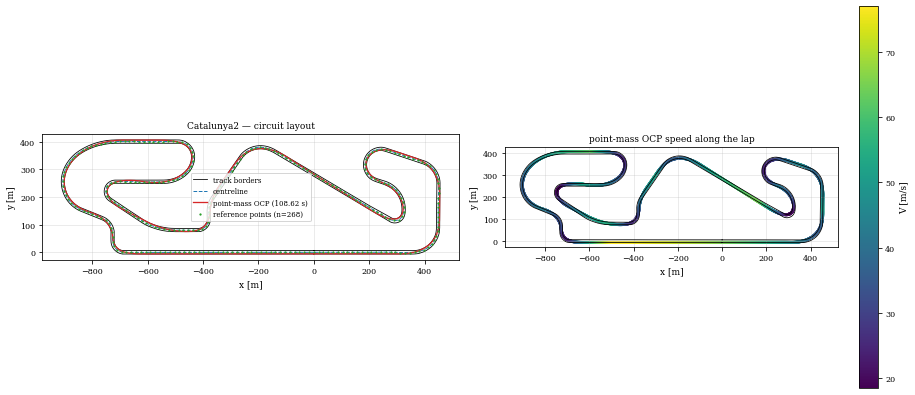

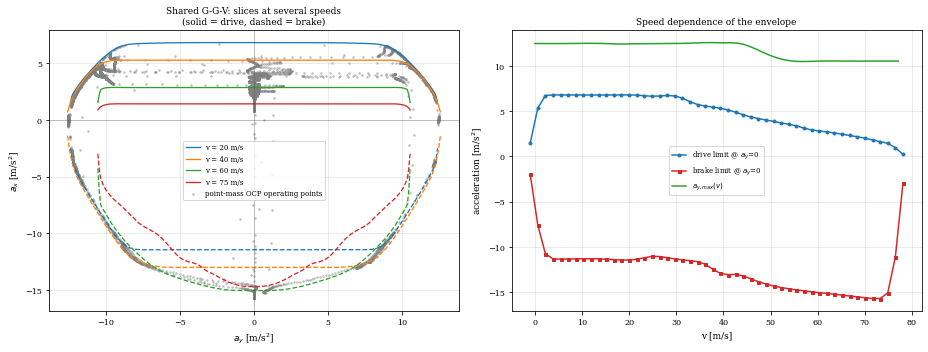

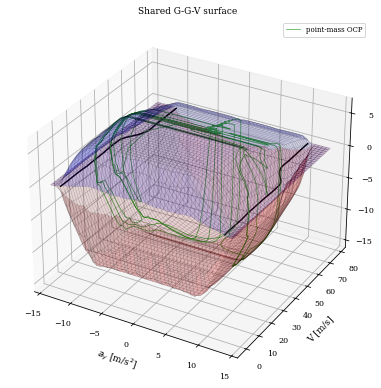

In [4]:
# ===========================================================================
# The circuit: borders, centreline, and the point-mass OCP trajectory
# ===========================================================================
(_bl_x, _bl_y), (_br_x, _br_y) = track_borders(road_df['x_mid_line'], road_df['y_mid_line'],
                                               road_df['dir_mid_line'],
                                               road_df['width_no_kerbs_L'],
                                               road_df['width_no_kerbs_R'])

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 5.6))

axA.plot(_bl_x, _bl_y, 'k-', lw=0.8, label='track borders')
axA.plot(_br_x, _br_y, 'k-', lw=0.8)
axA.plot(road_df['x_mid_line'], road_df['y_mid_line'], '--', color='tab:blue', lw=1.0,
         label='centreline')
axA.plot(pm_df['x_traj'], pm_df['y_traj'], '-', color='tab:red', lw=1.3,
         label=f"point-mass OCP ({PM_LAP:.2f} s)")
axA.plot(reftrack[:, 0], reftrack[:, 1], '.', color='tab:green', ms=2.5,
         label=f'reference points (n={reftrack.shape[0]})')
axA.set_aspect('equal'); axA.set_xlabel('x [m]'); axA.set_ylabel('y [m]')
axA.set_title(f'{CIRCUIT} — circuit layout'); axA.grid(True, alpha=0.3); axA.legend(fontsize=7)

sc = axB.scatter(pm_df['x_traj'], pm_df['y_traj'], c=pm_df['V'], cmap='viridis', s=4)
axB.plot(_bl_x, _bl_y, 'k-', lw=0.8)
axB.plot(_br_x, _br_y, 'k-', lw=0.8)
axB.set_aspect('equal'); axB.set_xlabel('x [m]'); axB.set_ylabel('y [m]')
axB.set_title('point-mass OCP speed along the lap'); axB.grid(True, alpha=0.3)
plt.colorbar(sc, ax=axB, label='V [m/s]')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'ggv_{CIRCUIT}_map.png'))
plt.show()

# ---------------------------------------------------------------------------
# The shared G-G-V envelope.
# Primary view is 2-D (slices at several speeds) because the 3-D projection is
# unavailable in some matplotlib installations; the 3-D surface of the shared
# script is attempted afterwards and skipped gracefully if Axes3D is missing.
# ---------------------------------------------------------------------------
fig, (axE, axF) = plt.subplots(1, 2, figsize=(13, 5))

_ay_fine = np.linspace(-G['ay_vec'].max(), G['ay_vec'].max(), 300)
for _v, _c in [(20.0, 'tab:blue'), (40.0, 'tab:orange'), (60.0, 'tab:green'), (75.0, 'tab:red')]:
    _up = [GG_UPPER(a, _v) for a in _ay_fine]
    _lo = [GG_LOWER(a, _v) for a in _ay_fine]
    _lim = GG_RANGE(_v)
    _m = np.abs(_ay_fine) <= _lim
    axE.plot(_ay_fine[_m], np.array(_up)[_m], '-',  color=_c, lw=1.3, label=f'v = {_v:g} m/s')
    axE.plot(_ay_fine[_m], np.array(_lo)[_m], '--', color=_c, lw=1.3)
axE.scatter(pm_df['ay'], pm_df['ax'], s=3, c='gray', alpha=0.35,
            label='point-mass OCP operating points', zorder=0)
axE.axhline(0, color='k', lw=0.5, alpha=0.4); axE.axvline(0, color='k', lw=0.5, alpha=0.4)
axE.set_xlabel('$a_y$ [m/s$^2$]'); axE.set_ylabel('$a_x$ [m/s$^2$]')
axE.set_title('Shared G-G-V: slices at several speeds\n(solid = drive, dashed = brake)')
axE.grid(True, alpha=0.3); axE.legend(fontsize=7)

axF.plot(G['vel_vec'], G['ax_max_grid'][:, int(np.argmin(np.abs(G['ay_vec'])))],
         'o-', color='tab:blue', ms=3, label='drive limit @ $a_y$=0')
axF.plot(G['vel_vec'], G['ax_min_grid'][:, int(np.argmin(np.abs(G['ay_vec'])))],
         's-', color='tab:red', ms=3, label='brake limit @ $a_y$=0')
axF.plot(G['vel_vec_lat'], G['ay_max_vec'], '-', color='tab:green', label='$a_{y,max}(v)$')
axF.set_xlabel('v [m/s]'); axF.set_ylabel('acceleration [m/s$^2$]')
axF.set_title('Speed dependence of the envelope')
axF.grid(True, alpha=0.3); axF.legend(fontsize=7)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'ggv_{CIRCUIT}_envelope.png'))
plt.show()

# optional 3-D surface (as in the shared script) — skipped if Axes3D is unavailable
try:
    from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
    ay_grid, vel_grid = np.meshgrid(G['ay_vec'], G['vel_vec'])
    fig = plt.figure(figsize=(7, 5.5))
    ax3d = fig.add_subplot(111, projection='3d')
    ax3d.plot_surface(ay_grid, vel_grid, G['ax_max_grid'], color='b', alpha=0.15,
                      edgecolor='black', linewidth=0.4)
    ax3d.plot_surface(ay_grid, vel_grid, G['ax_min_grid'], color='r', alpha=0.15,
                      edgecolor='black', linewidth=0.4)
    ax3d.plot(G['ay_max_vec'],  G['vel_vec_lat'], np.zeros_like(G['ay_max_vec']), 'k-')
    ax3d.plot(-G['ay_max_vec'], G['vel_vec_lat'], np.zeros_like(G['ay_max_vec']), 'k-')
    ax3d.plot(pm_df['ay'], pm_df['V'], pm_df['ax'], color='tab:green', lw=0.7,
              alpha=0.9, label='point-mass OCP')
    ax3d.set_xlabel('$a_y$ [m/s$^2$]'); ax3d.set_ylabel('V [m/s]'); ax3d.set_zlabel('$a_x$ [m/s$^2$]')
    ax3d.set_title('Shared G-G-V surface'); ax3d.legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'ggv_{CIRCUIT}_envelope_3d.png'))
    plt.show()
except Exception as _e:
    print(f"  (3-D surface skipped: {type(_e).__name__}: {str(_e)[:70]})")


In [ ]:
# ===========================================================================
# Results collector + reference rows
#   (a) their MLT-DT solution as given
#   (b) our OptiLine fb2d profile on THEIR trajectory curvature  -> validates that
#       the shared G-G-V is consumed correctly through gg_upper/gg_lower/gg_range
# ===========================================================================
results = []

def add(label, group, laptime, s, vx, sec, raceline=None, note="",
        kappa=None, el=None, ax=None, ay=None, laptime_xy=None,
        sd=0.0, prof_runs=None):
    # laptime_xy: for the shared reference solutions only -- the same solution's
    # lap time re-integrated along its own Cartesian (x, y) path, i.e. on the same
    # length scale as every OptiLine row.
    s  = np.asarray(s, float); vx = np.asarray(vx, float)
    n  = min(len(s), len(vx)); s, vx = s[:n], vx[:n]
    results.append(dict(label=label, group=group, laptime=float(laptime),
                        sd=float(sd), prof_runs=prof_runs,
                        s=s, vx=vx, sec=float(sec), raceline=raceline, note=note,
                        kappa=kappa, el=el, ax=ax, ay=ay,
                        laptime_xy=None if laptime_xy is None else float(laptime_xy)))
    _spread = "" if sd == 0.0 else f" +- {sd:6.3f}"
    print(f"  {label:28s} lap = {float(laptime):8.3f}{_spread} s   ({sec:6.1f} s)")

print(f"=== {CIRCUIT} benchmark ===")


add("Point-mass OCP", "reference", PM_LAP,
    pm_df['abscissa'].values, pm_df['V'].values, 0.0,
    raceline=np.column_stack([pm_df['x_traj'].values, pm_df['y_traj'].values]),
    kappa=pm_df['kappa_path'].values, ax=pm_df['ax'].values, ay=pm_df['ay'].values,
    laptime_xy=PM_LAP_XY,
    note="shared point-mass OCP solution (MLTS-point-mass), lap time as exported")


add("MLT-DT", "reference", DT_LAP,
    dt_df['abscissa'].values, dt_df['V'].values, 0.0,
    raceline=np.column_stack([dt_df['x_traj'].values, dt_df['y_traj'].values]),
    kappa=dt_df['kappa_path'].values, ax=dt_df['ax'].values, ay=dt_df['ay'].values,
    laptime_xy=DT_LAP_XY,
    note="shared MLT double-track solution, lap time as exported (ax/ay rescaled from g)")


_t0 = time.time()
_s_pm   = pm_df['s_driven'].values
_kap_pm = pm_df['kappa_path'].values
_el_pm  = np.diff(_s_pm)
_vx_pm, _ax_pm = calc_vel_profile_fb2d(
    ax_max_machines=AXMACH_TAB, ggv=None, v_max=V_MAX,
    kappa=_kap_pm, el_lengths=_el_pm, closed=False,
    v_start=float(pm_df['V'].values[0]),
    drag_coeff=VEH2['drag_coeff'], m_veh=VEH2['m_veh'],
    gg_upper=GG_UPPER, gg_lower=GG_LOWER, gg_range=GG_RANGE, return_accel=True)
_t_pm = float(calc_t_profile(vx_profile=_vx_pm, el_lengths=_el_pm)[-1])
add("fb2d on point-mass line", "reference", _t_pm, _s_pm, _vx_pm, time.time() - _t0,
    raceline=np.column_stack([pm_df['x_traj'].values, pm_df['y_traj'].values]),
    kappa=_kap_pm, el=_el_pm, ax=_ax_pm,
    note="sanity check: same path + same G-G-V as the point-mass OCP")

print(f"\n  sanity check vs the point-mass OCP: dt = {_t_pm - PM_LAP:+.3f} s, "
      f"mean|dV| = {np.mean(np.abs(_vx_pm - pm_df['V'].values)):.3f} m/s, "
      f"max|dV| = {np.max(np.abs(_vx_pm - pm_df['V'].values)):.3f} m/s")


=== Catalunya2 benchmark ===
  Point-mass OCP               lap =  108.615 s   (   0.0 s)
  MLT-DT                       lap =  109.399 s   (   0.0 s)
  fb2d on point-mass line      lap =  108.359 s   (   0.1 s)

  sanity check vs the point-mass OCP: dt = -0.256 s, mean|dV| = 0.087 m/s, max|dV| = 0.294 m/s


In [ ]:
# ===========================================================================
# Where the two reconstructions differ, and why it is confined to high speed
# ===========================================================================
_j0 = int(np.argmin(np.abs(G['ay_vec'])))
print("the tabulated grid at a_y ~ 0, near the top of the speed range:")
print(f"  {'v [m/s]':>9}{'ax_max':>9}{'ax_min':>9}")
for _i in range(len(G['vel_vec']) - 6, len(G['vel_vec'])):
    print(f"  {G['vel_vec'][_i]:>9.2f}{G['ax_max_grid'][_i, _j0]:>9.3f}"
          f"{G['ax_min_grid'][_i, _j0]:>9.3f}")
_bad = (G['ax_max_grid'].max(axis=1) - G['ax_min_grid'].min(axis=1)) < 1e-3
print(f"\n  fully collapsed rows: {[f'{x:.2f}' for x in G['vel_vec'][_bad]]}")
print(f"  the brake taper below them starts around 74 m/s and is also part of the fit")

# how much of the lap is actually spent up there?
_v_pm = pm_df['V'].values
for _thr in (70.0, 74.0, 76.0):
    print(f"  point-mass OCP spends {100 * np.mean(_v_pm > _thr):5.1f} % of its samples "
          f"above {_thr:.0f} m/s")


the tabulated grid at a_y ~ 0, near the top of the speed range:
    v [m/s]   ax_max   ax_min
      70.03    2.022  -15.623
      71.65    1.826  -15.707
      73.26    1.641  -15.709
      74.88    1.452  -15.086
      76.49    0.960  -11.116
      78.11    0.242   -2.947

  fully collapsed rows: []
  the brake taper below them starts around 74 m/s and is also part of the fit
  point-mass OCP spends   8.3 % of its samples above 70 m/s
  point-mass OCP spends   4.4 % of its samples above 74 m/s
  point-mass OCP spends   1.8 % of its samples above 76 m/s


In [ ]:
# ===========================================================================
# Validation: the two envelope reconstructions, side by side
#
# utils.load_ggv_envelope offers two readings of the same JSON:
#   'mlts'   via mlts_point_mass.GGVConstr -- normalises each row onto
#            s = ay / ay_max(v), enforces |ax| non-increasing with ay, and drops
#            speeds where the envelope has collapsed. This is what the point-mass
#            OCP is constrained with.
#   'linear' bilinear interpolation straight on the tabulated grid.
#
# ===========================================================================
_ENV_LIN = load_ggv_envelope(GGV_FILE, interp='linear')
_ENV_MLT = load_ggv_envelope(GGV_FILE, interp='mlts')

print("drive / brake limits at a_y = 0")
print(f"  {'v [m/s]':>9}{'drive mlts':>12}{'drive lin':>11}{'brake mlts':>12}{'brake lin':>11}")
print("  " + "-" * 56)
for _v in (20, 40, 60, 70, 74, 76):
    print(f"  {_v:>9}{_ENV_MLT['gg_upper'](0., _v):>12.3f}{_ENV_LIN['gg_upper'](0., _v):>11.3f}"
          f"{_ENV_MLT['gg_lower'](0., _v):>12.3f}{_ENV_LIN['gg_lower'](0., _v):>11.3f}")

# agreement over the whole envelope, away from the degenerate top rows
_rng = np.random.default_rng(0)
_pts = np.column_stack([_rng.uniform(5.0, 70.0, 3000),
                        _rng.uniform(-G['ay_vec'].max(), G['ay_vec'].max(), 3000)])
_du = max(abs(_ENV_MLT['gg_upper'](a, v) - _ENV_LIN['gg_upper'](a, v)) for v, a in _pts)
_dl = max(abs(_ENV_MLT['gg_lower'](a, v) - _ENV_LIN['gg_lower'](a, v)) for v, a in _pts)
print(f"\n  max |difference| over 3000 random (v, a_y) with v <= 70 m/s: "
      f"drive {_du:.4f}, brake {_dl:.4f} m/s^2")

# what it costs a lap
def _profile_with(env, kappa, el):
    return calc_vel_profile_fb2d(
        ax_max_machines=AXMACH_TAB, ggv=None, v_max=env['v_max'],
        kappa=kappa, el_lengths=el, closed=True,
        drag_coeff=VEH2['drag_coeff'], m_veh=VEH2['m_veh'],
        gg_upper=env['gg_upper'], gg_lower=env['gg_lower'], gg_range=env['gg_range'],
        filt_window=VEH2['fw'])

print("\nlap time by reconstruction (same raceline, same vehicle)")
print(f"  {'raceline':<10}{'mlts':>10}{'linear':>10}{'linear - mlts':>16}")
print("  " + "-" * 48)
for _name, _solve in (("SP", solve_shortestpath), ("MC", solve_mincurv)):
    _alpha, _nv = _solve(reftrack)
    _rl, _kap, _el = raceline_from_alpha(reftrack, _nv, _alpha, stepsize_interp=SI)
    _tm = laptime_closed(_profile_with(_ENV_MLT, _kap, _el), _el)
    _tl = laptime_closed(_profile_with(_ENV_LIN, _kap, _el), _el)
    print(f"  {_name:<10}{_tm:>10.3f}{_tl:>10.3f}{_tl - _tm:>+16.3f}")
print("  " + "-" * 48)
print("""  The 'linear' reading is the stricter one, purely because of the collapsed
  top-speed rows. Holding our methods to it while the reference OCP uses the
  'mlts' construction would bias the comparison against us, which is why
  GGV_INTERP defaults to 'mlts'.""")


drive / brake limits at a_y = 0
    v [m/s]  drive mlts  drive lin  brake mlts  brake lin
  --------------------------------------------------------
         20       6.803      6.805     -11.447    -11.454
         40       5.257      5.256     -12.997    -12.991
         60       2.842      2.842     -15.038    -15.038
         70       2.024      2.026     -15.620    -15.621
         74       1.555      1.554     -15.427    -15.424
         76       1.112      1.110     -12.374    -12.324

  max |difference| over 3000 random (v, a_y) with v <= 70 m/s: drive 3.1384, brake 6.7168 m/s^2

lap time by reconstruction (same raceline, same vehicle)
  raceline        mlts    linear   linear - mlts
  ------------------------------------------------
  SP           119.940   119.881          -0.058
  MC           110.464   110.647          +0.183
  ------------------------------------------------
  The 'linear' reading is the stricter one, purely because of the collapsed
  top-speed rows. Holdi

In [8]:
# ===========================================================================
# Geometric baselines: shortest path and minimum curvature
# Each raceline is evaluated with BOTH velocity profilers on the shared G-G-V.
# ===========================================================================
geo = {}
for gname, solve in (("SP", solve_shortestpath), ("MC", solve_mincurv)):
    t0 = time.time()
    alpha, normvec = solve(reftrack)
    rl, kappa, el = raceline_from_alpha(reftrack, normvec, alpha, stepsize_interp=SI)
    t_geo = time.time() - t0
    geo[gname] = dict(alpha=alpha, normvec=normvec, raceline=rl, kappa=kappa, el=el)
    t1 = time.time()
    _lap_si = laptime_closed(vel_profile(kappa, el, mode='fb2d',
                                         filt_window=VEH2['fw']), el)
    _lapF, _sF, _vxF, _rlF, _kapF, _elF = refine_at_si(alpha, normvec)
    add(f"{gname} (fb2d)", "geometric", _lapF, _sF, _vxF,
        t_geo + (time.time() - t1), raceline=_rlF, kappa=_kapF, el=_elF)
    print(f"      {gname}: SI={SI} -> {_lap_si:.4f} s | SI_FINAL={SI_FINAL} -> "
          f"{_lapF:.4f} s  ({_lapF - _lap_si:+.4f})")

# ---------------------------------------------------------------------------
# Single reference point for the vanilla point-mass profiler.
# Every other method uses fb2d with the shared envelope; this one row quantifies
# what is lost when that envelope is forced into OptiLine's [v, ax, ay] + exponent
# format (see the projection-loss cell below).
# ---------------------------------------------------------------------------

# _t1 = time.time()
# _vx_proj = vel_profile(geo['MC']['kappa'], geo['MC']['el'], mode='fb',
#                        filt_window=VEH2['fw'])
# add("MC (fb, projected G-G-V)", "geometric", laptime_closed(_vx_proj, geo['MC']['el']),
#     arc_length(geo['MC']['el']), _vx_proj, time.time() - _t1,
#     raceline=geo['MC']['raceline'],
#     note="vanilla point-mass profiler on the projected envelope (approximation)")

  SP (fb2d)                    lap =  119.532 s   (   0.7 s)
      SP: SI=4.0 -> 119.9396 s | SI_FINAL=1.0 -> 119.5320 s  (-0.4076)
  MC (fb2d)                    lap =  110.195 s   (   1.0 s)
      MC: SI=4.0 -> 110.4641 s | SI_FINAL=1.0 -> 110.1949 s  (-0.2691)


In [9]:
# ===========================================================================
# Direct blackbox alpha optimisation (Blackbox_raceline), ZORM and CMA-ES,
# on the shared G-G-V. mincurv warm start.
#
# Both solvers are stochastic, so each is run N_REPEATS times. The reported lap
# time is the mean with its sample standard deviation; everything plotted in x-y
# comes from the median run.
# ===========================================================================
bb_hist = {}                                   # convergence curves, per solver

for vel, tag in (('fb2d', 'fb2d'),):
    for sol in ('ZO', 'CMA'):
        n_it = BBA['iters_ZO'] if sol == 'ZO' else BBA['iters_CMA']
        lt_r, sec_r, h_r, out_r = [], [], [], []

        for q in range(N_REPEATS):
            t0 = time.time()
            bb = build_bba(reftrack, vel_solver=vel, n_iter=n_it, init='mincurv')
            if sol == 'ZO':
                a_opt, hist = bb.find_alpha(solver='ZO', n_iter=n_it, verbose=False)
            else:
                a_opt, hist = bb.find_alpha(solver='CMA', n_iter=n_it,
                                            popsize=BBA['popsize'], sigma=BBA['sigma'],
                                            verbose=False)
            _si_opt = bb.si
            bb.si = SI_FINAL                   # exact re-evaluation of the same alpha
            s_k, vx_k, ax_k, kap_k, tp_k, rl_k = bb.generate_raceline(a_opt)
            bb.si = _si_opt
            lt_r.append(float(tp_k[-1])); sec_r.append(time.time() - t0)
            h_r.append(np.asarray(hist, float))
            out_r.append((s_k, vx_k, ax_k, kap_k, rl_k, bb.alpha_0.copy(),
                          np.asarray(a_opt, float), bb.mu, bb.h, bb.t))
            print(f"      Blackbox {sol} run {q + 1}/{N_REPEATS}: "
                  f"optimiser SI={_si_opt} -> {hist[-1]:.4f} s | "
                  f"SI_FINAL={SI_FINAL} -> {tp_k[-1]:.4f} s")

        lt_m, lt_sd = agg(lt_r)
        sec_m, _ = agg(sec_r)
        j = median_idx(lt_r)
        s_k, vx_k, ax_k, kap_k, rl_k, a0_j, aopt_j, mu_j, h_j, t_j = out_r[j]
        add(f"Blackbox {sol} ({tag})", "blackbox", lt_m, s_k, vx_k, sec_m,
            raceline=rl_k, kappa=kap_k, ax=ax_k, sd=lt_sd,
            prof_runs=[(o[0], o[1]) for o in out_r])

        bb_hist[sol] = dict(hist=h_r[j], hist_runs=h_r,
                            alpha_0=a0_j, alpha_opt=aopt_j,
                            mu=mu_j, h=h_j, t=t_j,
                            sigma=BBA['sigma'], popsize=BBA['popsize'], n_iter=n_it)
        np.savez(os.path.join(FIG_DIR, f'bb_hist_{sol}.npz'),
                 **{k: v for k, v in bb_hist[sol].items() if k != 'hist_runs'})

# quick readout, on the median run
for sol, dd in bb_hist.items():
    h = dd['hist']
    n_impr = int(np.sum(np.diff(h) < -1e-9))
    first = int(np.argmin(h))
    moved = float(np.max(np.abs(dd['alpha_opt'] - dd['alpha_0'])))
    print(f"{sol:4s}: {h[0]:.4f} -> {h[-1]:.4f}  (gain {h[0] - h[-1]:+.4f} s) | "
          f"improving iters: {n_impr}/{len(h) - 1} | best reached at iter {first} | "
          f"max|alpha-alpha_0| = {moved:.4f} m")


      Blackbox ZO run 1/3: optimiser SI=4.0 -> 109.9203 s | SI_FINAL=1.0 -> 109.6949 s
      Blackbox ZO run 2/3: optimiser SI=4.0 -> 109.9182 s | SI_FINAL=1.0 -> 109.6939 s
      Blackbox ZO run 3/3: optimiser SI=4.0 -> 109.9224 s | SI_FINAL=1.0 -> 109.6980 s
  Blackbox ZO (fb2d)           lap =  109.696 +-  0.002 s   ( 380.4 s)
Fb2d::BW() >> No solution found for segment 53
Fb2d::BW() >> No solution found for segment 53
Fb2d::BW() >> No solution found for segment 53
Fb2d::BW() >> No solution found for segment 52
Fb2d::BW() >> No solution found for segment 53
Fb2d::BW() >> No solution found for segment 53
Fb2d::BW() >> No solution found for segment 53
Fb2d::BW() >> No solution found for segment 53
Fb2d::BW() >> No solution found for segment 53
Fb2d::BW() >> No solution found for segment 53
Fb2d::BW() >> No solution found for segment 53
Fb2d::BW() >> No solution found for segment 53
Fb2d::BW() >> No solution found for segment 53
Fb2d::BW() >> No solution found for segment 53
Fb2d::BW()

In [10]:
# ===========================================================================
# Bilevel zeroth-order optimisation (Opt_min_CurvTime), ZORM and CMA-ES,
# on the shared G-G-V. Repeated N_REPEATS times, as for the blackbox rows.
# ===========================================================================
for vel, tag in (('fb2d', 'fb2d'),):
    for sol in ('ZO', 'CMA'):
        lt_r, sec_r, out_r = [], [], []

        for q in range(N_REPEATS):
            t0 = time.time()
            opt = build_optct(reftrack, vel_solver=vel)
            ds, hist = opt.CurveLenOpt(solver=sol)
            _si_opt = opt.si
            opt.si = SI_FINAL                 # exact re-evaluation of the same solution
            s_b, vx_b, ax_b, kap_b, tp_b, rl_b = opt.generate_kinProfs(ds=ds)
            opt.si = _si_opt
            lt_r.append(float(tp_b[-1])); sec_r.append(time.time() - t0)
            out_r.append((s_b, vx_b, ax_b, kap_b, rl_b))
            print(f"      Bilevel {sol} run {q + 1}/{N_REPEATS}: "
                  f"optimiser SI={_si_opt} -> {hist[-1]:.4f} s | "
                  f"SI_FINAL={SI_FINAL} -> {tp_b[-1]:.4f} s")

        lt_m, lt_sd = agg(lt_r)
        sec_m, _ = agg(sec_r)
        j = median_idx(lt_r)
        s_b, vx_b, ax_b, kap_b, rl_b = out_r[j]
        add(f"Bilevel {sol} ({tag})", "bilevel", lt_m, s_b, vx_b, sec_m,
            raceline=rl_b, kappa=kap_b, ax=ax_b, sd=lt_sd,
            prof_runs=[(o[0], o[1]) for o in out_r])


      Bilevel ZO run 1/3: optimiser SI=4.0 -> 110.4404 s | SI_FINAL=1.0 -> 110.1937 s
      Bilevel ZO run 2/3: optimiser SI=4.0 -> 110.4404 s | SI_FINAL=1.0 -> 110.1936 s
      Bilevel ZO run 3/3: optimiser SI=4.0 -> 110.4409 s | SI_FINAL=1.0 -> 110.1941 s
  Bilevel ZO (fb2d)            lap =  110.194 +-  0.000 s   (  42.2 s)
      Bilevel CMA run 1/3: optimiser SI=4.0 -> 110.4281 s | SI_FINAL=1.0 -> 110.1828 s
      Bilevel CMA run 2/3: optimiser SI=4.0 -> 110.4297 s | SI_FINAL=1.0 -> 110.1849 s
      Bilevel CMA run 3/3: optimiser SI=4.0 -> 110.4269 s | SI_FINAL=1.0 -> 110.1806 s
  Bilevel CMA (fb2d)           lap =  110.183 +-  0.002 s   (  83.0 s)


In [11]:
# ===========================================================================
# Lap-time and runtime summary
# ===========================================================================
_ref = next((r['laptime'] for r in results if r['label'] == "Point-mass OCP"), np.nan)

print("\n" + "=" * 84)
print(f"  {CIRCUIT}: lap time & runtime (all non-OCP methods use the shared G-G-V)")
print("=" * 84)
print(f"  {'method':<30}{'group':<11}{'lap [s]':>10}{'d vs OCP':>13}{'runtime [s]':>13}")
print("  " + "-" * 78)
for r in sorted(results, key=lambda d: d['laptime']):
    _lap = (f"{r['laptime']:.3f}" if r.get('sd', 0.0) == 0.0
            else f"{r['laptime']:.3f}+-{r['sd']:.3f}")
    print(f"  {r['label']:<30}{r['group']:<11}{_lap:>16}"
          f"{r['laptime'] - _ref:>+13.3f}{r['sec']:>13.1f}")
print("  " + "-" * 78)
print(f"  {'TOTAL runtime':<30}{'':<11}{'':>10}{'':>13}"
      f"{sum(r['sec'] for r in results):>13.1f}")
print("=" * 84)
for r in results:
    if r['note']:
        print(f"  note: {r['label']} — {r['note']}")

# --- the shared references on both length scales ---------------------------------
_two = [r for r in results if r.get('laptime_xy') is not None]
if _two:
    print("\n" + "=" * 84)
    print("  Shared reference solutions on the two length scales")
    print("=" * 84)
    print(f"  {'solution':<20}{'exported (zeta)':>18}{'re-integrated on (x,y)':>25}{'difference':>14}")
    print("  " + "-" * 78)
    for r in _two:
        print(f"  {r['label']:<20}{r['laptime']:>18.3f}{r['laptime_xy']:>25.3f}"
              f"{r['laptime_xy'] - r['laptime']:>+14.3f}")
    print("  " + "-" * 78)
    print("""  zeta (= the road file's abscissa, the OCP's independent coordinate) totals
  4721.67 m, while the polyline through the tabulated mid-line it parameterises is
  4672.77 m. The 1.05% sits entirely in the corners and chord-to-arc from the
  tabulated curvature explains 0.03 m of it. Every OptiLine row above is integrated
  along the Cartesian path, so the right-hand column is the like-for-like
  comparison; the left-hand column is what the shared files report.""")
    print("=" * 84)

# LaTeX-ready table
print("\n% ---- LaTeX ----")
print("\\begin{tabular}{llrr}\n\\toprule")
print("Method & Velocity model & Lap time [s] & Runtime [s] \\\\\n\\midrule")
for r in sorted(results, key=lambda d: d['laptime']):
    _lab = r['label'].replace('_', '\\_')
    if '(' in _lab and _lab.endswith(')'):
        _m, _v = _lab.rsplit('(', 1); _m, _v = _m.strip(), _v[:-1]
    else:
        _m, _v = _lab, '--'
    _lap = (f"{r['laptime']:.3f}" if r.get('sd', 0.0) == 0.0
            else f"${r['laptime']:.3f} \\pm {r['sd']:.3f}$")
    print(f"{_m} & {_v} & {_lap} & {r['sec']:.1f} \\\\")
print("\\bottomrule\n\\end{tabular}")


  Catalunya2: lap time & runtime (all non-OCP methods use the shared G-G-V)
  method                        group         lap [s]     d vs OCP  runtime [s]
  ------------------------------------------------------------------------------
  fb2d on point-mass line       reference           108.359       -0.256          0.1
  Point-mass OCP                reference           108.615       +0.000          0.0
  MLT-DT                        reference           109.399       +0.783          0.0
  Blackbox CMA (fb2d)           blackbox     109.512+-0.010       +0.896        372.0
  Blackbox ZO (fb2d)            blackbox     109.696+-0.002       +1.080        380.4
  Bilevel CMA (fb2d)            bilevel      110.183+-0.002       +1.567         83.0
  Bilevel ZO (fb2d)             bilevel      110.194+-0.000       +1.578         42.2
  MC (fb2d)                     geometric           110.195       +1.580          1.0
  SP (fb2d)                     geometric           119.532      +10.917  

In [12]:
# ===========================================================================
# The two length signals, and what they cost once the speeds are re-solved
#
# FBGA needs `kappa` and `el_lengths` in the SAME metric. On the previous track export
# that was a live problem: its abscissa was 1.05 % longer than the polyline through its
# own mid-line, so the lap time the OCP reported disagreed with the time implied by the
# path it returned by 1.4488 s, and re-profiling moved by ~3 s depending on which signal
# was used. The corrected export removes the ambiguity; this cell confirms it.
#
# STANDALONE: reads only pm_df and the envelope, and does not append to `results`.
# ===========================================================================
def _fb_lap(kappa, el, v0):
    _vx = calc_vel_profile_fb2d(
        ax_max_machines=AXMACH_TAB, ggv=None, v_max=V_MAX,
        kappa=kappa, el_lengths=el, closed=False, v_start=v0,
        drag_coeff=VEH2['drag_coeff'], m_veh=VEH2['m_veh'],
        gg_upper=GG_UPPER, gg_lower=GG_LOWER, gg_range=GG_RANGE)
    return float(calc_t_profile(vx_profile=_vx, el_lengths=el)[-1])


print("=" * 84)
print(f"  {CIRCUIT}: point-mass OCP reference on each length signal")
print("=" * 84)
_V   = pm_df['V'].values
_elz = np.diff(pm_df['abscissa'].values)        # centreline abscissa
_elc = np.diff(pm_df['s_driven'].values)        # driven Cartesian path
_kap = pm_df['kappa_path'].values

print(f"  {'':<34}{'abscissa el':>14}{'Cartesian el':>15}{'difference':>13}")
print("  " + "-" * 78)
print(f"  {'its own speeds':<34}{PM_LAP:>14.4f}"
      f"{float(np.sum(2.0 * _elc / (_V[:-1] + _V[1:]))):>15.4f}"
      f"{float(np.sum(2.0 * _elc / (_V[:-1] + _V[1:]))) - PM_LAP:>+13.4f}")
_fz = _fb_lap(_kap, _elz, float(_V[0]))
_fc = _fb_lap(_kap, _elc, float(_V[0]))
print(f"  {'FBGA on the same path':<34}{_fz:>14.4f}{_fc:>15.4f}{_fc - _fz:>+13.4f}")
print("  " + "-" * 78)
print(f"  track abscissa {pm_df['abscissa'].values[-1]:.2f} m, "
      f"driven path {pm_df['s_driven'].values[-1]:.2f} m")
print("=" * 84)


  Catalunya2: point-mass OCP reference on each length signal
                                       abscissa el   Cartesian el   difference
  ------------------------------------------------------------------------------
  its own speeds                          108.6154       108.6151      -0.0002
  FBGA on the same path                   110.7001       108.3594      -2.3407
  ------------------------------------------------------------------------------
  track abscissa 4650.39 m, driven path 4582.67 m


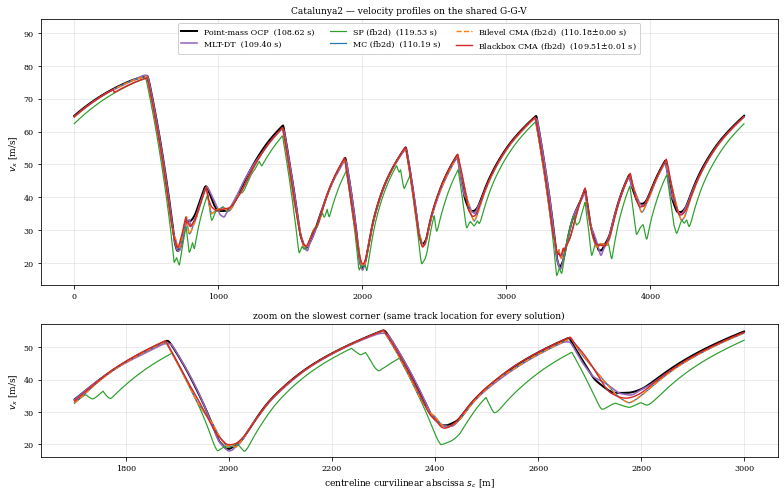

velocity-profile figure shows:
   Point-mass OCP           108.615 s
   MLT-DT                   109.399 s
   SP (fb2d)                119.532 s
   MC (fb2d)                110.195 s
   Bilevel CMA (fb2d)       110.183 s
   Blackbox CMA (fb2d)      109.512 s


In [ ]:
# ===========================================================================
# Figure: velocity profiles -- point-mass OCP, SP, MC, best bilevel, best blackbox
# (only the better of the two outer solvers is shown for each optimiser)
# ===========================================================================
def _row(label):
    return next((r for r in results if r['label'] == label), None)


def _best_of(group):
    _c = [r for r in results if r['group'] == group and 'projected' not in r['label']]
    return min(_c, key=lambda r: r['laptime']) if _c else None


_sel = [(_row("Point-mass OCP"), 'k',          '-',  2.0),
        (_row("MLT-DT"),         'tab:purple', '-',  1.6),
        (_row("SP (fb2d)"),     'tab:green',  '-',  1.2),
        (_row("MC (fb2d)"),     'tab:blue',   '-',  1.2),
        (_best_of('bilevel'),   'tab:orange', '--', 1.4),
        (_best_of('blackbox'),  'tab:red',    '-',  1.4)]
_sel = [(r, c, ls, lw) for r, c, ls, lw in _sel
        if r is not None and r['raceline'] is not None]

# projection onto the centreline abscissa, shared with the next cell
PROJ = {r['label']: to_centreline(r) for r, *_ in _sel}

fig, (axv, axz) = plt.subplots(2, 1, figsize=(11, 7),
                               gridspec_kw={'height_ratios': [2, 1]})
for r, col, ls, lw in _sel:
    _sc, _D, _vx, _off = PROJ[r['label']]
    _lbl = (f"{r['label']}  ({r['laptime']:.2f} s)" if r.get('sd', 0.0) == 0.0
            else f"{r['label']}  ({r['laptime']:.2f}$\\pm${r['sd']:.2f} s)")
    axv.plot(_sc, _vx, ls, color=col, lw=lw, label=_lbl)
    # +/- one std across the repeats, mapped onto the same centreline abscissa
    if r.get('prof_runs'):
        _st = []
        for _sq, _vq in r['prof_runs']:
            _sq = np.asarray(_sq, float); _vq = np.asarray(_vq, float)
            _m2 = min(len(_sq), len(_vq))
            _u = (_sq[:_m2] - _sq[0]) / max(_sq[_m2 - 1] - _sq[0], 1e-9)
            _st.append(np.interp(np.linspace(0, 1, len(_sc)), _u, _vq[:_m2]))
        _A = np.vstack(_st)
        if _A.shape[0] > 1:
            _mu, _sd = _A.mean(axis=0), _A.std(axis=0, ddof=1)
            axv.fill_between(_sc, _mu - _sd, _mu + _sd, color=col, alpha=0.15, lw=0)
axv.set_ylabel('$v_x$ [m/s]')
axv.set_title(f'{CIRCUIT} — velocity profiles on the shared G-G-V')
axv.grid(True, alpha=0.3)
# headroom so the legend sits above the traces instead of over a velocity peak
_vtop = max(np.max(PROJ[r['label']][2]) for r, *_ in _sel)
axv.set_ylim(top=_vtop * 1.22)
axv.legend(fontsize=8, loc='upper center', ncol=3, framealpha=0.9)

# zoom on the slowest part of the lap, where the methods differ most
_scM, _, _vxM, _ = PROJ["Point-mass OCP"]
_i0 = int(np.argmin(_vxM))
_s0, _s1 = _scM[_i0] - 300.0, _scM[_i0] + 1000.0
for r, col, ls, lw in _sel:
    _sc, _D, _vx, _off = PROJ[r['label']]
    _m = (_sc >= _s0) & (_sc <= _s1)
    axz.plot(_sc[_m], _vx[_m], ls, color=col, lw=lw)
axz.set_xlabel('centreline curvilinear abscissa $s_c$ [m]')
axz.set_ylabel('$v_x$ [m/s]')
axz.set_title('zoom on the slowest corner (same track location for every solution)')
axz.grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig(os.path.join(FIG_DIR, f'ggv_{CIRCUIT}_velprofiles.png'))
plt.savefig(os.path.join(FIG_DIR, f'ggv_{CIRCUIT}_velprofiles.pdf'))
plt.show()

print("velocity-profile figure shows:")
for r, *_ in _sel:
    print(f"   {r['label']:<24}{r['laptime']:8.3f} s")


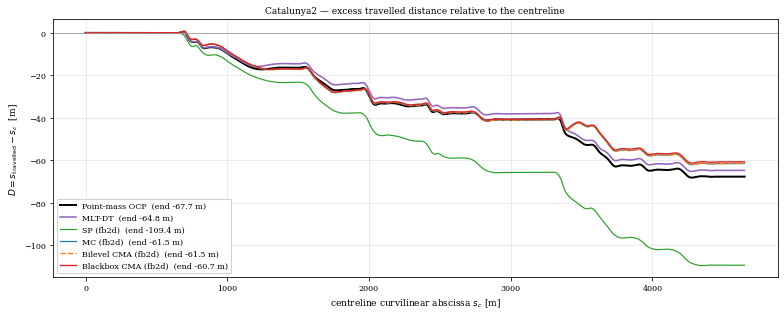


solution                        path len [m]  vs centreline  mean |offset|   lap [s]
------------------------------------------------------------------------------------
Point-mass OCP                        4582.7          -67.7           3.70   108.615
MLT-DT                                4584.0          -64.8           3.22   109.399
SP (fb2d)                             4540.0         -109.4           4.46   119.532
MC (fb2d)                             4587.9          -61.5           3.22   110.195
Bilevel CMA (fb2d)                    4587.9          -61.5           3.21   110.183
Blackbox CMA (fb2d)                   4588.7          -60.7           3.20   109.512
------------------------------------------------------------------------------------
centreline                            4650.4           +0.0           0.00


In [ ]:
fig, axd = plt.subplots(1, 1, figsize=(11, 4.5))

for r, col, ls, lw in _sel:
    _sc, _D, _vx, _off = PROJ[r['label']]
    axd.plot(
        _sc, _D, ls, color=col, lw=lw,
        label=f"{r['label']}  (end {_D[-1]:+.1f} m)"
    )

axd.axhline(0.0, color='0.6', lw=0.8)
axd.set_xlabel('centreline curvilinear abscissa $s_c$ [m]')
axd.set_ylabel('$D = s_\\mathrm{travelled} - s_c$  [m]')
axd.set_title(f'{CIRCUIT} — excess travelled distance relative to the centreline')
axd.grid(True, alpha=0.3)
axd.legend(fontsize=8, loc='best', framealpha=0.9)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'ggv_{CIRCUIT}_pathlength_excess.pdf'))
plt.show()

# --- summary -------------------------------------------------------------------
print(f"\n{'solution':<30}{'path len [m]':>14}{'vs centreline':>15}"
      f"{'mean |offset|':>15}{'lap [s]':>10}")
print("-" * 84)
for r, *_ in _sel:
    _sc, _D, _vx, _off = PROJ[r['label']]
    print(f"{r['label']:<30}{_sc[-1] + _D[-1]:>14.1f}{_D[-1]:>+15.1f}"
          f"{_off.mean():>15.2f}{r['laptime']:>10.3f}")
print("-" * 84)
print(f"{'centreline':<30}{CL['L']:>14.1f}{0.0:>+15.1f}{0.0:>15.2f}")


best OptiLine method: Blackbox CMA (fb2d)  (109.512 s)   vs point-mass OCP 108.615 s   -> +0.896 s


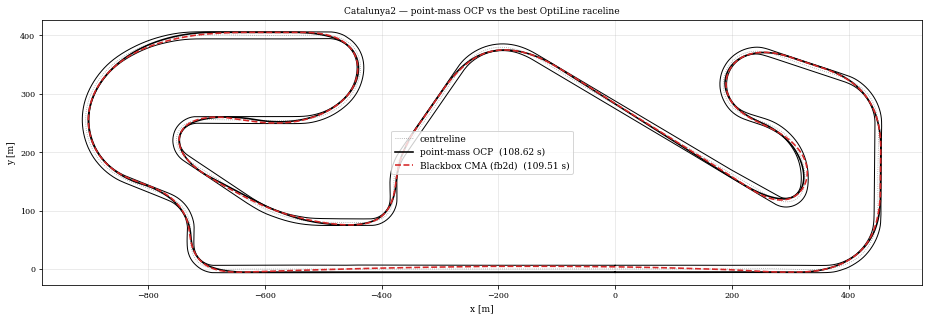

In [15]:
# ===========================================================================
# Figure: the circuit with the point-mass OCP and the best OptiLine raceline
# ===========================================================================
_mlt = next(r for r in results if r['label'] == "Point-mass OCP")
_cand = [r for r in results if r['group'] in ('geometric', 'bilevel', 'blackbox')
         and 'projected' not in r['label'] and r['raceline'] is not None]
_best = min(_cand, key=lambda r: r['laptime'])
print(f"best OptiLine method: {_best['label']}  ({_best['laptime']:.3f} s)   "
      f"vs point-mass OCP {_mlt['laptime']:.3f} s   -> {_best['laptime'] - _mlt['laptime']:+.3f} s")

_rl_b = np.asarray(_best['raceline'], float)
_rl_m = np.asarray(_mlt['raceline'], float)

fig, ax = plt.subplots(figsize=(13, 6.5))
(_bl_x, _bl_y), (_br_x, _br_y) = track_borders(road_df['x_mid_line'], road_df['y_mid_line'],
                                               road_df['dir_mid_line'],
                                               road_df['width_no_kerbs_L'],
                                               road_df['width_no_kerbs_R'])
ax.plot(_bl_x, _bl_y, 'k-', lw=1.0)
ax.plot(_br_x, _br_y, 'k-', lw=1.0)
ax.plot(road_df['x_mid_line'], road_df['y_mid_line'], ':', color='0.6', lw=0.8,
        label='centreline')
ax.plot(_rl_m[:, 0], _rl_m[:, 1], '-',  color='k',       lw=1.6,
        label=f"point-mass OCP  ({_mlt['laptime']:.2f} s)")
ax.plot(_rl_b[:, 0], _rl_b[:, 1], '--', color='tab:red', lw=1.6,
        label=f"{_best['label']}  ({_best['laptime']:.2f} s)")
ax.set_aspect('equal'); ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
ax.set_title(f'{CIRCUIT} — point-mass OCP vs the best OptiLine raceline')
ax.grid(True, alpha=0.3); ax.legend(fontsize=9, loc='best')
plt.tight_layout()
# plt.savefig(os.path.join(FIG_DIR, f'ggv_{CIRCUIT}_racelines.png'))
plt.savefig(os.path.join(FIG_DIR, f'ggv_{CIRCUIT}_racelines.pdf'))
plt.show()

In [ ]:

print("=" * 78)
print(f"  {CIRCUIT} — numbers for the manuscript")
print("=" * 78)

# --- (a) lap times ---------------------------------------------------------
print("\n[1] Lap times")
for r in sorted(results, key=lambda d: d['laptime']):
    print(f"    {r['label']:<26}{r['laptime']:8.3f} s   ({r['sec']:6.1f} s runtime)")

# --- (b) vehicle envelope: why min-curvature is already near-optimal --------
_j0 = int(np.argmin(np.abs(G['ay_vec'])))
_drive = G['ax_max_grid'][:, _j0]
_aymax = np.interp(G['vel_vec'], G['vel_vec_lat'], G['ay_max_vec'])
_ok = (G['vel_vec'] > 10) & (G['vel_vec'] < 70)
print("\n[2] Vehicle envelope (shared G-G-V)")
print(f"    ay_max            : {G['ay_max_vec'].max():.2f} m/s^2 (nearly flat in v)")
print(f"    drive @ low / high: {_drive[_ok][0]:.2f} / {_drive[_ok][-1]:.2f} m/s^2 (power-limited)")
print(f"    drive / ay_max    : {np.median(_drive[_ok] / _aymax[_ok]):.2f}"
      "      (1.00 on the small F1Tenth-scale car)")
# washout of a corner-exit speed advantage
for _v in (40.0, 60.0):
    _lam = -(GG_UPPER(0.0, _v + 1.0) - GG_UPPER(0.0, _v))
    print(f"    exit-speed washout @ {_v:.0f} m/s: time constant "
          f"{1.0 / _lam if _lam > 0 else float('inf'):.1f} s on a {results[0]['laptime']:.0f} s lap")

# --- (c) why ZORM stalls but CMA-ES does not --------------------------------
print("\n[3] Blackbox landscape at the minimum-curvature warm start")
_bb = build_bba(reftrack, vel_solver='fb2d', n_iter=1, init='mincurv')
_a0 = _bb.alpha_0.copy(); _n = len(_a0)
_c0 = _bb._laptime_cost(_a0)
_rng = np.random.default_rng(); _g = np.zeros(_n)
for _ in range(12):
    _u = _rng.standard_normal(_n)
    _g += (_bb._laptime_cost(_a0 + 1e-4 * _u) - _c0) / 1e-4 * _u
_g /= 20
print(f"    ||grad C||               : {np.linalg.norm(_g):8.1f}")
print(f"    ||grad C|| / lap time    : {np.linalg.norm(_g) / _c0:8.3f}"
      "   (6.24 on the small Catalunya)")
print("    => the minimum-curvature line is already near-stationary here, so a")
print("       fixed-step projected ZO method has almost nothing to descend, while")
print("       CMA-ES still finds the shallow improvement by sampling further out.")
if 'bb_hist' in globals():
    for _s, _d in bb_hist.items():
        _h = np.asarray(_d['hist'], float)
        print(f"    {_s:<4}: gain {_h[0] - _h[-1]:+.4f} s | improving iters "
              f"{int(np.sum(np.diff(_h) < -1e-9))}/{len(_h) - 1} | "
              f"max|alpha-alpha_0| = {np.max(np.abs(_d['alpha_opt'] - _d['alpha_0'])):.4f} m")

# --- (d) cross-check against the shared scripts -----------------------------
print("\n[4] Cross-check with the shared scripts")
print(f"    point-mass OCP reference          : {PM_LAP:.3f} s")
print(f"    our fb2d on the point-mass line   : "
      f"{next(r['laptime'] for r in results if 'fb2d on point-mass' in r['label']):.3f} s")
print(f"    (115.598 s was main_fbga_solution.py on the earlier 20x20 g-g-v)")
print(f"    envelope agreement vs setup_fbga  : ~1e-14 (see the validation cell)")
print("=" * 78)

  Catalunya2 — numbers for the manuscript

[1] Lap times
    fb2d on point-mass line    108.359 s   (   0.1 s runtime)
    Point-mass OCP             108.615 s   (   0.0 s runtime)
    MLT-DT                     109.399 s   (   0.0 s runtime)
    Blackbox CMA (fb2d)        109.512 s   ( 372.0 s runtime)
    Blackbox ZO (fb2d)         109.696 s   ( 380.4 s runtime)
    Bilevel CMA (fb2d)         110.183 s   (  83.0 s runtime)
    Bilevel ZO (fb2d)          110.194 s   (  42.2 s runtime)
    MC (fb2d)                  110.195 s   (   1.0 s runtime)
    SP (fb2d)                  119.532 s   (   0.7 s runtime)

[2] Vehicle envelope (shared G-G-V)
    ay_max            : 12.59 m/s^2 (nearly flat in v)
    drive @ low / high: 6.80 / 2.18 m/s^2 (power-limited)
    drive / ay_max    : 0.42      (1.00 on the small F1Tenth-scale car)
    exit-speed washout @ 40 m/s: time constant 8.2 s on a 109 s lap
    exit-speed washout @ 60 m/s: time constant 15.7 s on a 109 s lap

[3] Blackbox landscape at

Below is diagnosis codes

In [17]:
# ===========================================================================
# DIAGNOSIS 1 -- are all methods really solving the same problem?
# Before interpreting that result we audit every input that could make the comparison
# unfair: the drivable corridor, the safety margin, the envelope, the drag and
# mass, and the velocity-profile filtering.
# ===========================================================================
print("=" * 78)
print("  INPUT CONSISTENCY AUDIT")
print("=" * 78)

# --- 1. corridor and safety margin --------------------------------------------
# The corridor now VARIES along the lap, so the audit has to be done against the
# local half-width at each station rather than against a single number.
_wR = road_df['width_no_kerbs_R'].values
_wL = road_df['width_no_kerbs_L'].values
_ab_rd = road_df['abscissa'].values
_sfty = VEH2['w_veh'] / 2.0

_n_pm = pm_df['n'].values
_wL_pm = np.interp(pm_df['abscissa'].values, _ab_rd, _wL)
_wR_pm = np.interp(pm_df['abscissa'].values, _ab_rd, _wR)
_slack_L = _wL_pm - _n_pm                        # clearance to the left edge
_slack_R = _wR_pm + _n_pm                        # clearance to the right edge

print("\n[1] Drivable corridor (varying half-widths)")
print(f"    half-width right          : {_wR.min():.3f} .. {_wR.max():.3f} m")
print(f"    half-width left           : {_wL.min():.3f} .. {_wL.max():.3f} m")
print(f"    point-mass lateral offset : {_n_pm.min():+.3f} .. {_n_pm.max():+.3f} m")
print(f"    point-mass min clearance  : L {_slack_L.min():.3f} / R {_slack_R.min():.3f} m")
print(f"    our safety margin w_veh/2 : {_sfty:.3f} m   (w_veh = {VEH2['w_veh']:.3f} m)")
_margin_pm = min(_slack_L.min(), _slack_R.min())
_dm = abs(_sfty - _margin_pm)
print(f"    -> the point-mass OCP keeps {_margin_pm:.3f} m of clearance at its tightest "
      f"point; we thin the corridor by {_sfty:.3f} m")
print(f"    -> MATCH to {_dm:.4f} m" if _dm < 0.05 else
      f"    -> differ by {_dm:.3f} m (both use w_veh = {VEH2['w_veh']} m, so this is "
      f"where the OCP simply did not need the full width)")

# --- 2. sub-sampling: are the corridor constraints actually enforced? ------------
print("\n[2] Centreline sub-sampling (STEP = %d)" % STEP)
_spf = np.hypot(*np.diff(reftrack_full[:, :2], axis=0).T)
_spr = np.hypot(*np.diff(reftrack[:, :2], axis=0).T)
print(f"    full centreline : {reftrack_full.shape[0]:5d} pts, spacing {_spf.mean():.2f} m")
print(f"    optimiser track : {reftrack.shape[0]:5d} pts, spacing {_spr.mean():.2f} m")
print("""
    The QP constrains |alpha| <= half-width - w_veh/2 only AT the nodes, while the
    raceline is a spline interpolated between them, so it can bulge OUTSIDE the
    corridor in between. Refining the node spacing measures that overshoot:""")
_lim = min(reftrack_full[:, 2].min(), reftrack_full[:, 3].min()) - _sfty
print(f"\n    allowed |n| <= {_lim:.3f} m   (narrowest point of a varying corridor)")
print(f"    {'STEP':>5}{'nodes':>7}{'spacing':>9}  {'method':<4}{'max|n|':>9}{'excess':>9}{'lap [s]':>10}")
print("    " + "-" * 53)
for _st in sorted({STEP, 8, 4}, reverse=True):
    _rt, _ = load_catalunya2(road_df, step=_st)
    _sp = np.hypot(*np.diff(_rt[:, :2], axis=0).T).mean()
    for _nm, _solve in (("SP", solve_shortestpath), ("MC", solve_mincurv)):
        _al, _nv = _solve(_rt)
        _rl, _kp, _elx = raceline_from_alpha(_rt, _nv, _al, stepsize_interp=SI)
        _, _of = project_to_centreline(CL, _rl)
        _lp = laptime_closed(vel_profile(_kp, _elx, 'fb2d', filt_window=VEH2['fw']), _elx)
        print(f"    {_st:>5}{_rt.shape[0]:>7}{_sp:>9.2f}  {_nm:<4}{_of.max():>9.3f}"
              f"{_of.max() - _lim:>+9.3f}{_lp:>10.3f}")
print("""
    -> the overshoot shrinks monotonically with the node spacing, confirming it is
       spline interpolation between constraint nodes rather than a corridor error.
       """)

# --- 3. vehicle / envelope inputs ----------------------------------------------
print("\n[3] Shared inputs for every velocity profile")
print(f"    drag_coeff = {VEH2['drag_coeff']}   m_veh = {VEH2['m_veh']}   v_max = {V_MAX:.2f} m/s")
print(f"    envelope   : identical gg_upper / gg_lower / gg_range callables for all methods")
print(f"    ay_max     : {G['ay_max_vec'].min():.2f} .. {G['ay_max_vec'].max():.2f} m/s^2")



# --- 4. curvature ---------------------------------------------------------------
print("\n[5] Path curvature (the actual mechanism)")
print(f"    {'solution':<24}{'mean|k|':>10}{'max|k|':>10}")
for _k in ('SP', 'MC'):
    _ka = np.abs(geo[_k]['kappa'])
    print(f"    {_k:<24}{_ka.mean():>10.5f}{_ka.max():>10.5f}")
_kp = np.abs(pm_df['kappa_path'].values)
print(f"    {'Point-mass OCP':<24}{_kp.mean():>10.5f}{_kp.max():>10.5f}")
_kc = np.abs(road_df['curvature'].values)
print(f"    {'centreline (road file)':<24}{_kc.mean():>10.5f}{_kc.max():>10.5f}")



  INPUT CONSISTENCY AUDIT

[1] Drivable corridor (varying half-widths)
    half-width right          : 4.588 .. 8.980 m
    half-width left           : 4.475 .. 7.834 m
    point-mass lateral offset : -5.482 .. +5.890 m
    point-mass min clearance  : L 0.829 / R 0.829 m
    our safety margin w_veh/2 : 0.900 m   (w_veh = 1.800 m)
    -> the point-mass OCP keeps 0.829 m of clearance at its tightest point; we thin the corridor by 0.900 m
    -> differ by 0.071 m (both use w_veh = 1.8 m, so this is where the OCP simply did not need the full width)

[2] Centreline sub-sampling (STEP = 12)
    full centreline :  3213 pts, spacing 1.45 m
    optimiser track :   268 pts, spacing 17.33 m

    The QP constrains |alpha| <= half-width - w_veh/2 only AT the nodes, while the
    raceline is a spline interpolated between them, so it can bulge OUTSIDE the
    corridor in between. Refining the node spacing measures that overshoot:

    allowed |n| <= 3.575 m   (narrowest point of a varying corridor)
 

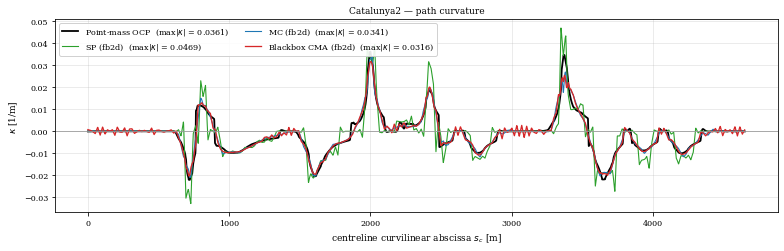

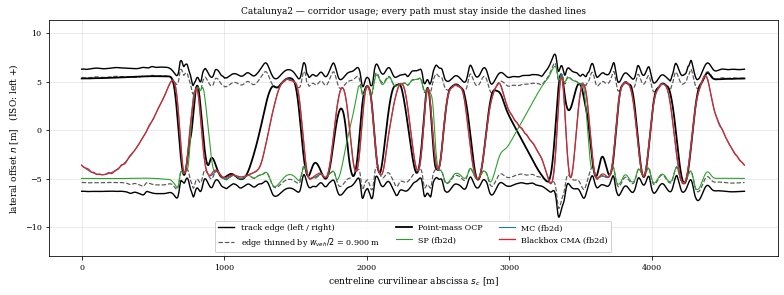


solution                    max n    min n   worst margin to thinned edge
--------------------------------------------------------------------------
Point-mass OCP             +5.890   -5.481                         -0.071  <-- OUTSIDE
SP (fb2d)                  +6.580   -6.137                         -0.296  <-- OUTSIDE
MC (fb2d)                  +5.755   -5.447                         -0.054  <-- OUTSIDE
Blackbox CMA (fb2d)        +5.606   -5.544                         -0.076  <-- OUTSIDE


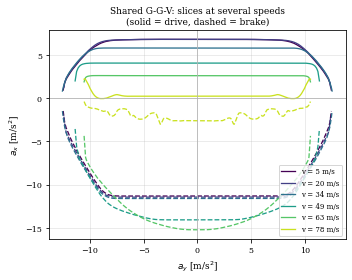

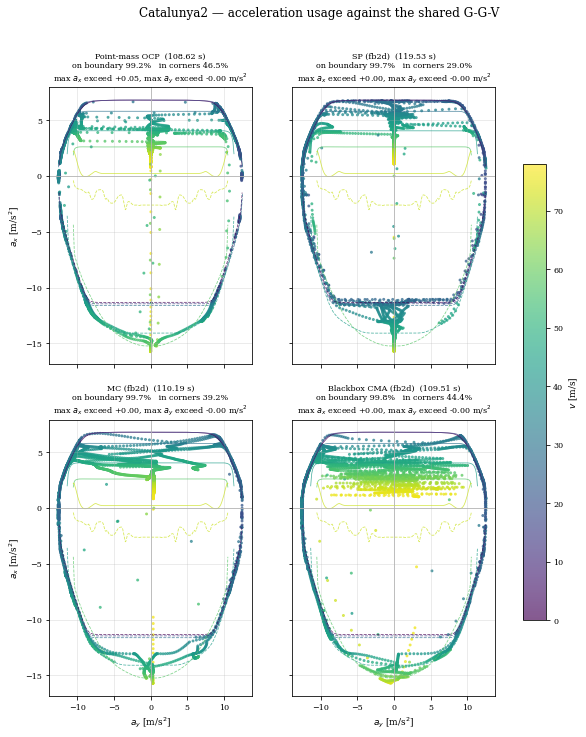


solution                 mean |ax|/lim mean |ay|/lim  on boundary  in corners   lap [s]
---------------------------------------------------------------------------------------
Point-mass OCP                   0.921         0.536        99.2%       46.5%   108.615
SP (fb2d)                        0.967         0.352        99.7%       29.0%   119.532
MC (fb2d)                        0.970         0.502        99.7%       39.2%   110.195
Blackbox CMA (fb2d)              0.969         0.577        99.8%       44.4%   109.512
---------------------------------------------------------------------------------------

  'on boundary' = fraction of the lap with hypot(|ax|/ax_lim, |ay|/ay_max) > 0.95
  'in corners'  = fraction with BOTH ratios > 0.7, i.e. combined braking/driving
                  and cornering simultaneously.


In [18]:
# ===========================================================================
# DIAGNOSIS 2 -- corridor usage and envelope usage of each solution
#
# Four solutions are compared on the centreline abscissa: the shared point-mass OCP,
# SP, MC and the best direct-blackbox raceline. All are checked against the SAME
# corridor and the SAME g-g-v envelope. Note the corridor now varies along the lap,
# so the dashed limits in Figure B are curves rather than straight lines.
# ===========================================================================

# --- signed lateral offset (ISO: left positive, right negative) ----------------
# --- corridor half-widths as functions of the centreline abscissa ---------------
_ab = road_df['abscissa'].values
def wL_at(sc): return np.interp(np.mod(sc, CL['L']), _ab, road_df['width_no_kerbs_L'].values)
def wR_at(sc): return np.interp(np.mod(sc, CL['L']), _ab, road_df['width_no_kerbs_R'].values)

SFTY = VEH2['w_veh'] / 2.0

# --- the four solutions ---------------------------------------------------------
def _row(label):
    return next((r for r in results if r['label'] == label), None)

def _best_of(group):
    _c = [r for r in results if r['group'] == group and 'projected' not in r['label']]
    return min(_c, key=lambda r: r['laptime']) if _c else None

DIAG = [(_row("Point-mass OCP"), 'k',          '-',  1.8),
        (_row("SP (fb2d)"),    'tab:green',  '-',  1.1),
        (_row("MC (fb2d)"),    'tab:blue',   '-',  1.1),
        (_best_of('blackbox'), 'tab:red',    '-',  1.3)]
DIAG = [(r, c, ls, lw) for r, c, ls, lw in DIAG
        if r is not None and r['raceline'] is not None]


def kinematics(r):
    '''(s_c, n_signed, kappa, vx, ax, ay) for one result row, on the common coordinate.'''
    _rl = np.asarray(r['raceline'], float)
    _sc, _n = project_signed(CL, _rl)
    _sc = _sc - _sc[0]
    _vx = np.asarray(r['vx'], float)
    _kap = r.get('kappa')
    _kap = np.asarray(_kap, float) if _kap is not None else np.full(len(_vx), np.nan)
    # accelerations: prefer the values produced by the solver, else derive them
    if r.get('ay') is not None:
        _ay = np.asarray(r['ay'], float)
    else:
        _m = min(len(_vx), len(_kap))
        _ay = _vx[:_m] ** 2 * _kap[:_m]
    if r.get('ax') is not None:
        _ax = np.asarray(r['ax'], float)
    else:
        _el = np.asarray(r['el'], float) if r.get('el') is not None else np.diff(_sc)
        _m = min(len(_vx), len(_el) + 1)
        _ax = calc_ax_profile(vx_profile=_vx[:_m], el_lengths=_el[:_m - 1],
                              eq_length_output=True)
    _m = min(len(_sc), len(_n), len(_kap), len(_vx), len(_ax), len(_ay))
    return _sc[:_m], _n[:_m], _kap[:_m], _vx[:_m], _ax[:_m], _ay[:_m]


KIN = {r['label']: kinematics(r) for r, *_ in DIAG}

# ===========================================================================
# Figure A -- curvature along the lap
# ===========================================================================
fig, ax1 = plt.subplots(figsize=(11, 3.6))
for r, col, ls, lw in DIAG:
    _sc, _n, _kap, _vx, _axp, _ay = KIN[r['label']]
    ax1.plot(_sc, _kap, ls, color=col, lw=lw,
             label=f"{r['label']}  (max|$\\kappa$| = {np.nanmax(np.abs(_kap)):.4f})")
ax1.axhline(0.0, color='0.6', lw=0.8)
ax1.set_xlabel('centreline curvilinear abscissa $s_c$ [m]')
ax1.set_ylabel(r'$\kappa$ [1/m]')
ax1.set_title(f'{CIRCUIT} — path curvature')
ax1.grid(True, alpha=0.3); ax1.legend(fontsize=8, ncol=2, loc='best', framealpha=0.9)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'diag_{CIRCUIT}_curvature.pdf'))
plt.show()

# ===========================================================================
# Figure B -- lateral offset against the corridor and the thinned corridor
# ===========================================================================
_sg = np.linspace(0.0, CL['L'], 2000)
fig, ax2 = plt.subplots(figsize=(11, 4.2))
ax2.plot(_sg,  wL_at(_sg), '-',  color='k', lw=1.4, label='track edge (left / right)')
ax2.plot(_sg, -wR_at(_sg), '-',  color='k', lw=1.4)
ax2.plot(_sg,  wL_at(_sg) - SFTY, '--', color='0.35', lw=1.2,
         label=f'edge thinned by $w_{{veh}}/2$ = {SFTY:.3f} m')
ax2.plot(_sg, -wR_at(_sg) + SFTY, '--', color='0.35', lw=1.2)
for r, col, ls, lw in DIAG:
    _sc, _n, _kap, _vx, _axp, _ay = KIN[r['label']]
    ax2.plot(_sc, _n, ls, color=col, lw=lw, label=r['label'])
ax2.set_xlabel('centreline curvilinear abscissa $s_c$ [m]')
ax2.set_ylabel('lateral offset $n$ [m]   (ISO: left +)')
ax2.set_title(f'{CIRCUIT} — corridor usage; every path must stay inside the dashed lines')
ax2.grid(True, alpha=0.3); ax2.legend(fontsize=8, ncol=3, loc='lower center', framealpha=0.9)
ax2.set_ylim(-wR_at(_sg).max() * 1.45, wL_at(_sg).max() * 1.45)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'diag_{CIRCUIT}_corridor.pdf'))
plt.show()

# numeric corridor check
print(f"\n{'solution':<24}{'max n':>9}{'min n':>9}{'worst margin to thinned edge':>31}")
print("-" * 74)
for r, *_ in DIAG:
    _sc, _n, _kap, _vx, _axp, _ay = KIN[r['label']]
    _mar = np.minimum(wL_at(_sc) - SFTY - _n, wR_at(_sc) - SFTY + _n)
    _flag = "  OK" if _mar.min() >= -1e-3 else "  <-- OUTSIDE"
    print(f"{r['label']:<24}{_n.max():>+9.3f}{_n.min():>+9.3f}{_mar.min():>+31.3f}{_flag}")

# ===========================================================================
# Figure C -- the shared G-G-V, sliced at several speeds
# ===========================================================================
_vsl = np.linspace(max(G['vel_vec'].min(), 5.0), G['vel_vec'].max(), 6)
_ayg = np.linspace(-G['ay_vec'].max(), G['ay_vec'].max(), 400)
fig, ax3 = plt.subplots(figsize=(5, 4))
_cm = plt.cm.viridis(np.linspace(0, 0.92, len(_vsl)))
for _c, _v in zip(_cm, _vsl):
    _aym = GG_RANGE(_v)
    _m = np.abs(_ayg) <= _aym
    ax3.plot(_ayg[_m], [GG_UPPER(a, _v) for a in _ayg[_m]], '-',  color=_c, lw=1.3,
             label=f'v = {_v:.0f} m/s')
    ax3.plot(_ayg[_m], [GG_LOWER(a, _v) for a in _ayg[_m]], '--', color=_c, lw=1.3)
ax3.axhline(0, color='0.7', lw=0.8); ax3.axvline(0, color='0.7', lw=0.8)
ax3.set_xlabel('$a_y$ [m/s$^2$]'); ax3.set_ylabel('$a_x$ [m/s$^2$]')
ax3.set_title('Shared G-G-V: slices at several speeds\n(solid = drive, dashed = brake)')
ax3.grid(True, alpha=0.3); ax3.legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'diag_{CIRCUIT}_ggv_slices.pdf'))
plt.show()

# ===========================================================================
# Figure D -- acceleration usage of each solution against the envelope
# ===========================================================================
USAGE = {}          # envelope-utilisation statistics, filled in per solution
_ncol = 3 if len(DIAG) > 4 else 2
_nrow = int(np.ceil(len(DIAG) / _ncol))
fig, axs = plt.subplots(_nrow, _ncol, figsize=(5.0 * _ncol, 5.6 * _nrow),
                        sharex=True, sharey=True, squeeze=False)
_axl = axs.ravel()
for _a, (r, col, ls, lw) in zip(_axl, DIAG):
    _sc, _n, _kap, _vx, _axp, _ay = KIN[r['label']]
    for _c, _v in zip(_cm, _vsl):                       # envelope for reference
        _aym = GG_RANGE(_v); _m = np.abs(_ayg) <= _aym
        _a.plot(_ayg[_m], [GG_UPPER(x, _v) for x in _ayg[_m]], '-',  color=_c, lw=0.8, alpha=0.75)
        _a.plot(_ayg[_m], [GG_LOWER(x, _v) for x in _ayg[_m]], '--', color=_c, lw=0.8, alpha=0.75)
    _sc_p = _a.scatter(_ay, _axp, c=_vx, s=4, cmap='viridis', alpha=0.65,
                       vmin=0, vmax=G['vel_vec'].max())
    # how far outside the envelope does this solution go?
    _up = np.array([GG_UPPER(a, v) for a, v in zip(_ay, _vx)])
    _lo = np.array([GG_LOWER(a, v) for a, v in zip(_ay, _vx)])
    _exc = np.maximum(_axp - _up, _lo - _axp)
    _ayx = np.abs(_ay) - np.array([GG_RANGE(v) for v in _vx])

    # --- how much of the envelope is actually used? ----------------------------
    # Normalise each operating point by the local limit: u_x = |a_x| / a_x,lim(a_y, v)
    # and u_y = |a_y| / a_y,max(v). A point with hypot(u_x, u_y) close to 1 lies on
    # the envelope boundary; a point with BOTH ratios large sits in a "corner" of
    # the envelope, i.e. it is braking or driving hard while also cornering hard.
    _lim = np.where(_axp >= 0.0, _up, _lo)
    _ux = np.abs(_axp) / np.maximum(np.abs(_lim), 1e-9)
    _uy = np.abs(_ay) / np.maximum(np.array([GG_RANGE(v) for v in _vx]), 1e-9)
    _u = np.hypot(_ux, _uy)
    _f_bnd = 100.0 * np.mean(_u > 0.95)          # on the boundary
    _f_cor = 100.0 * np.mean((_ux > 0.7) & (_uy > 0.7))   # in a combined-load corner
    USAGE[r['label']] = dict(mean_ux=float(_ux.mean()), mean_uy=float(_uy.mean()),
                             frac_boundary=float(_f_bnd), frac_corner=float(_f_cor),
                             exc_ax=float(_exc.max()), exc_ay=float(_ayx.max()))

    _a.set_title(f"{r['label']}  ({r['laptime']:.2f} s)\n"
                 f"on boundary {_f_bnd:.1f}%   in corners {_f_cor:.1f}%\n"
                 f"max $a_x$ exceed {_exc.max():+.2f}, max $a_y$ exceed {_ayx.max():+.2f} m/s$^2$",
                 fontsize=8)
    _a.grid(True, alpha=0.3)
    _a.axhline(0, color='0.7', lw=0.8); _a.axvline(0, color='0.7', lw=0.8)
for _a in _axl[len(DIAG):]:                 # hide unused panels
    _a.axis('off')
for _i, _a in enumerate(_axl[:len(DIAG)]):
    if _i // _ncol == _nrow - 1 or _i + _ncol >= len(DIAG):
        _a.set_xlabel('$a_y$ [m/s$^2$]')
    if _i % _ncol == 0:
        _a.set_ylabel('$a_x$ [m/s$^2$]')
fig.colorbar(_sc_p, ax=axs, shrink=0.75, label='$v$ [m/s]')
fig.suptitle(f'{CIRCUIT} — acceleration usage against the shared G-G-V', y=0.98)
plt.savefig(os.path.join(FIG_DIR, f'diag_{CIRCUIT}_accel_scatter.pdf'))
plt.show()

print(f"\n{'solution':<24}{'mean |ax|/lim':>14}{'mean |ay|/lim':>14}"
      f"{'on boundary':>13}{'in corners':>12}{'lap [s]':>10}")
print("-" * 87)
for r, *_ in DIAG:
    _s = USAGE[r['label']]
    print(f"{r['label']:<24}{_s['mean_ux']:>14.3f}{_s['mean_uy']:>14.3f}"
          f"{_s['frac_boundary']:>12.1f}%{_s['frac_corner']:>11.1f}%{r['laptime']:>10.3f}")
print("-" * 87)
print("""
  'on boundary' = fraction of the lap with hypot(|ax|/ax_lim, |ay|/ay_max) > 0.95
  'in corners'  = fraction with BOTH ratios > 0.7, i.e. combined braking/driving
                  and cornering simultaneously.""")




  exact constraint g(ax, ay, V) <= 1 : g_max = 1.000000, 0.00 % of samples outside
  (the per-sample figures below are measured against the gridded lookup, which interpolates that same boundary)
  Where does the Point-mass OCP trace leave the fitted g-g-v?
  tabulated grid : v -1.00..78.11 m/s, a_y +/-13.86 m/s^2
  Point-mass OCP data   : v 18.55..76.94 m/s, a_y -12.57..12.50 m/s^2
  samples inside the grid: 4652/4652  -> no extrapolation involved

  exceedance distribution over the 4652 samples:
    >  0.0 m/s^2 :  906 samples (19.48 % of the lap)
    >  0.1 m/s^2 :    0 samples ( 0.00 % of the lap)
    >  1.0 m/s^2 :    0 samples ( 0.00 % of the lap)
    >  2.0 m/s^2 :    0 samples ( 0.00 % of the lap)
    of those, 819 on the DRIVE side (max 0.01) and 87 on the BRAKE side (max 0.05)

  contiguous stretches with exceedance > 0.1 m/s^2 (0 found, worst first):
          abscissa [m]   len       v     a_y     a_x  a_x limit  max exc    side
    (none)


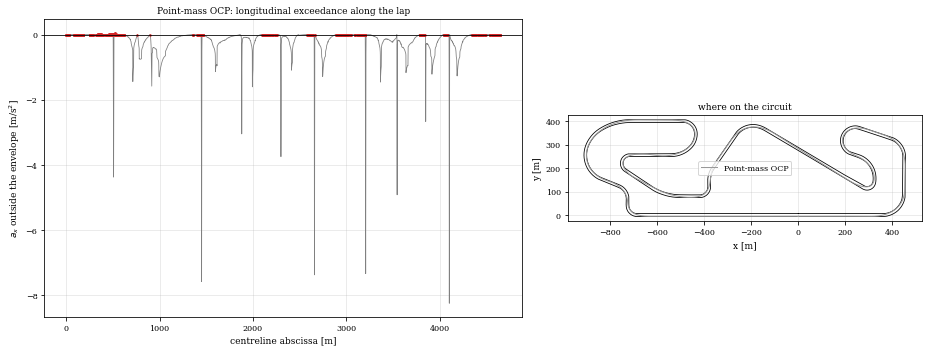


  exact constraint g(ax, ay, V) <= 1 : g_max = 1.558901, 52.10 % of samples outside
  (the per-sample figures below are measured against the gridded lookup, which interpolates that same boundary)
  Where does the MLT-DT trace leave the fitted g-g-v?
  tabulated grid : v -1.00..78.11 m/s, a_y +/-13.86 m/s^2
  MLT-DT data   : v 17.92..77.11 m/s, a_y -12.87..12.75 m/s^2
  samples inside the grid: 3002/3002  -> no extrapolation involved

  exceedance distribution over the 3002 samples:
    >  0.0 m/s^2 : 1244 samples (41.44 % of the lap)
    >  0.1 m/s^2 :  504 samples (16.79 % of the lap)
    >  1.0 m/s^2 :  213 samples ( 7.10 % of the lap)
    >  2.0 m/s^2 :   97 samples ( 3.23 % of the lap)
    of those, 854 on the DRIVE side (max 3.66) and 390 on the BRAKE side (max 2.73)

  contiguous stretches with exceedance > 0.1 m/s^2 (30 found, worst first):
          abscissa [m]   len       v     a_y     a_x  a_x limit  max exc    side
       1187-1295          71    50.4  -11.25    3.66      

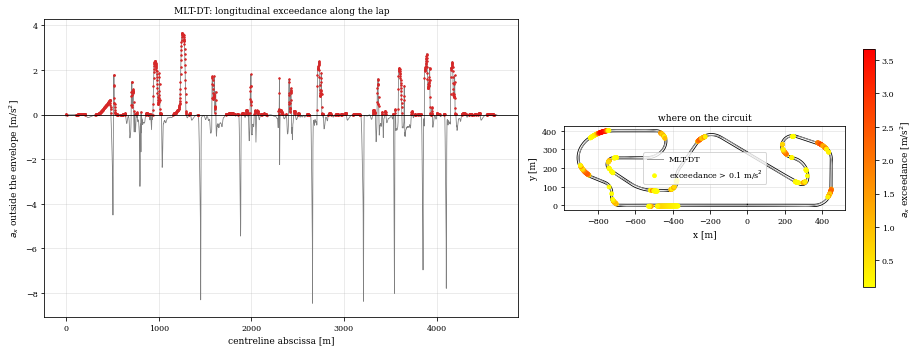

In [19]:
# ===========================================================================
# DIAGNOSIS 3 -- where does the shared reference trace leave the fitted g-g-v?
#
# The acceleration scatter shows whether the reference solution lies outside the fitted
# envelope at some points. This cell locates those points exactly: where on the
# track, at what speed and lateral load, and on the drive or the brake side.
#
# It first checks that every sample lies INSIDE the tabulated (v, a_y) grid, so
# that the exceedance cannot be an artefact of extrapolating our own lookup.
#
# The g-g-v is a FIT to the vehicle model, not a bound on it, so the solutions
# that produced it are under no obligation to stay inside.
# ===========================================================================
(_bl_x, _bl_y), (_br_x, _br_y) = track_borders(road_df['x_mid_line'], road_df['y_mid_line'],
                                               road_df['dir_mid_line'],
                                               road_df['width_no_kerbs_L'],
                                               road_df['width_no_kerbs_R'])

for _tag, _name, _df in (('pointmass', 'Point-mass OCP', pm_df),
                         ('mltdt',     'MLT-DT',         dt_df)):
    _v   = _df['V'].values
    _ay  = _df['ay'].values
    _ax  = _df['ax'].values
    _s   = _df['abscissa'].values

    _up  = np.array([GG_UPPER(a, vv) for a, vv in zip(_ay, _v)])
    _lo  = np.array([GG_LOWER(a, vv) for a, vv in zip(_ay, _v)])
    _exc = np.maximum(_ax - _up, _lo - _ax)          # >0 means outside the envelope

    # The gridded callables are an INTERPOLATION of the envelope boundary, so a
    # solution that rides that boundary reads as marginally outside them even when
    # it is exactly feasible. When the exact constraint is available, report it too:
    # that is the number to trust for a reference solution.
    if GG_EXACT is not None:
        _gv = np.asarray(GG_EXACT(np.vstack([_ax, _ay, _v]))).ravel()
        print(f"\n  exact constraint g(ax, ay, V) <= 1 : g_max = {_gv.max():.6f}, "
              f"{100 * np.mean(_gv > 1.0 + 1e-6):.2f} % of samples outside")
        print(f"  (the per-sample figures below are measured against the gridded "
              f"lookup, which interpolates that same boundary)")

    _in_grid = ((_v >= G['vel_vec'].min()) & (_v <= G['vel_vec'].max())
                & (np.abs(_ay) <= G['ay_vec'].max()))
    print("=" * 78)
    print(f"  Where does the {_name} trace leave the fitted g-g-v?")
    print("=" * 78)
    print(f"  tabulated grid : v {G['vel_vec'].min():.2f}..{G['vel_vec'].max():.2f} m/s, "
          f"a_y +/-{G['ay_vec'].max():.2f} m/s^2")
    print(f"  {_name} data   : v {_v.min():.2f}..{_v.max():.2f} m/s, "
          f"a_y {_ay.min():.2f}..{_ay.max():.2f} m/s^2")
    print(f"  samples inside the grid: {int(_in_grid.sum())}/{len(_v)}  "
          f"-> {'no extrapolation involved' if _in_grid.all() else 'SOME POINTS EXTRAPOLATED'}")

    print(f"\n  exceedance distribution over the {len(_exc)} samples:")
    for _th in (0.0, 0.1, 1.0, 2.0):
        print(f"    > {_th:4.1f} m/s^2 : {int((_exc > _th).sum()):4d} samples "
              f"({100 * np.mean(_exc > _th):5.2f} % of the lap)")
    _drv = (_exc > 0) & (_ax >= 0)
    _brk = (_exc > 0) & (_ax < 0)
    print(f"    of those, {int(_drv.sum())} on the DRIVE side "
          f"(max {_exc[_drv].max() if _drv.any() else 0:.2f}) and "
          f"{int(_brk.sum())} on the BRAKE side "
          f"(max {_exc[_brk].max() if _brk.any() else 0:.2f})")

    # --- group the exceeding samples into contiguous stretches of track ----------
    _idx = np.where(_exc > 0.1)[0]
    _grp = np.split(_idx, np.where(np.diff(_idx) > 3)[0] + 1) if _idx.size else []
    _grp = sorted([gp for gp in _grp if gp.size], key=lambda gp: -_exc[gp].max())
    print(f"\n  contiguous stretches with exceedance > 0.1 m/s^2 "
          f"({len(_grp)} found, worst first):")
    print(f"    {'abscissa [m]':>18}{'len':>6}{'v':>8}{'a_y':>8}{'a_x':>8}"
          f"{'a_x limit':>11}{'max exc':>9}{'side':>8}")
    for gp in _grp[:8]:
        _j = gp[int(np.argmax(_exc[gp]))]
        print(f"    {_s[gp[0]]:7.0f}-{_s[gp[-1]]:<10.0f}{gp.size:>6}{_v[_j]:>8.1f}"
              f"{_ay[_j]:>8.2f}{_ax[_j]:>8.2f}"
              f"{(_lo[_j] if _ax[_j] < 0 else _up[_j]):>11.2f}"
              f"{_exc[_j]:>9.2f}{'brake' if _ax[_j] < 0 else 'drive':>8}")
    if not _grp:
        print("    (none)")

    # --- figure: exceedance along the lap and on the map -------------------------
    fig, (axe, axm) = plt.subplots(1, 2, figsize=(13, 5),
                                   gridspec_kw={'width_ratios': [1.35, 1]})
    axe.plot(_s, _exc, '-', color='0.5', lw=0.8)
    axe.plot(_s[_exc > 0], _exc[_exc > 0], '.', color='tab:red', ms=3)
    axe.axhline(0.0, color='k', lw=0.8)
    axe.set_xlabel('centreline abscissa [m]')
    axe.set_ylabel('$a_x$ outside the envelope [m/s$^2$]')
    axe.set_title(f'{_name}: longitudinal exceedance along the lap')
    axe.grid(True, alpha=0.3)

    axm.plot(_bl_x, _bl_y, 'k-', lw=0.8)
    axm.plot(_br_x, _br_y, 'k-', lw=0.8)
    axm.plot(_df['x_traj'], _df['y_traj'], '-', color='0.6', lw=1.0, label=_name)
    _hot = _exc > 0.1
    if _hot.any():
        _sc_e = axm.scatter(_df['x_traj'].values[_hot], _df['y_traj'].values[_hot],
                            c=_exc[_hot], cmap='autumn_r', s=14, zorder=3,
                            label='exceedance > 0.1 m/s$^2$')
        fig.colorbar(_sc_e, ax=axm, shrink=0.8, label='$a_x$ exceedance [m/s$^2$]')
    axm.set_aspect('equal'); axm.set_xlabel('x [m]'); axm.set_ylabel('y [m]')
    axm.set_title('where on the circuit')
    axm.legend(fontsize=8, loc='best'); axm.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'diag_{CIRCUIT}_{_tag}_envelope_exceedance.pdf'))
    plt.show()



In [ ]:

CSV_DIR = os.path.join(FIG_DIR, f'{CIRCUIT}_OptiLine_solutions')
os.makedirs(CSV_DIR, exist_ok=True)

_absc = road_df['abscissa'].values
_xc, _yc = road_df['x_mid_line'].values, road_df['y_mid_line'].values


def export_solution(r, fname, time_override=None):
    '''Write one result row as a CSV mirroring the shared reference files.'''
    _sc, _n, _kap, _vx, _axp, _off = kinematics(r)
    _rl = np.asarray(r['raceline'], float)[:len(_sc)]

    # arc length along the driven raceline, closed with the wrap-around element
    _el_open = np.hypot(*np.diff(_rl, axis=0).T)
    _st = np.concatenate([[0.0], np.cumsum(_el_open)])
    _el_cl = np.append(_el_open, float(np.hypot(*(_rl[0] - _rl[-1]))))

    # cumulative time from the package profiler (same integrator as laptime_closed)
    _vx_cl = np.append(_vx, _vx[0])
    _ax_fb = calc_ax_profile(vx_profile=_vx_cl, el_lengths=_el_cl,
                             eq_length_output=False)
    _t = np.asarray(calc_t_profile(vx_profile=_vx, ax_profile=_ax_fb,
                                   el_lengths=_el_cl), float)
    if time_override is not None:
        # the reference solution carries its own (curvilinear, double-track) time;
        # re-integrating its speed along the Cartesian path is a different quantity
        # and would not reproduce the lap time stated in the shared file
        _t = np.asarray(time_override, float)

    _m = min(len(_sc), len(_rl), len(_st), len(_t), len(_vx), len(_axp), len(_kap))
    _scm = np.mod(_sc[:_m], CL['L'])
    df = pd.DataFrame({
        'abscissa'         : _sc[:_m],                       # centreline abscissa
        's_travelled'      : _st[:_m],                       # along this raceline
        'time'             : _t[:_m],
        'xTrj'             : _rl[:_m, 0],                    # the driven raceline
        'yTrj'             : _rl[:_m, 1],
        'x_proj'           : np.interp(_scm, _absc, _xc),    # projected onto centreline
        'y_proj'           : np.interp(_scm, _absc, _yc),
        'V'                : _vx[:_m],
        'ax_2D'            : _axp[:_m],
        'ay_2D'            : (_vx[:_m] ** 2 * _kap[:_m]) if r.get('ay') is None
                             else np.asarray(r['ay'], float)[:_m],
        'kappa'            : _kap[:_m],
        'width_no_kerbs_L' : wL_at(_scm),
        'width_no_kerbs_R' : wR_at(_scm),
    })
    _p = os.path.join(CSV_DIR, fname)
    df.to_csv(_p, index=False, float_format='%.6f')
    print(f"  {r['label']:<24} -> {_p}   ({len(df)} rows, lap {r['laptime']:.3f} s, "
          f"time at last row {df['time'].values[-1]:.3f} s "
          f"[+ closing element = lap])")
    return df


print(f"writing solution files to {CSV_DIR}/")
_exported = {}
for _r, _fn in ((_row("SP (fb2d)"),    'OptiLine_SP_Catalunya2.csv'),
                (_row("MC (fb2d)"),    'OptiLine_MC_Catalunya2.csv'),
                (_best_of('blackbox'), 'OptiLine_BBA_best_Catalunya2.csv')):
    if _r is not None and _r['raceline'] is not None:
        _exported[_r['label']] = export_solution(_r, _fn)



writing solution files to paper_figs/Catalunya2_OptiLine_solutions/
  SP (fb2d)                -> paper_figs/Catalunya2_OptiLine_solutions/OptiLine_SP_Catalunya2.csv   (4541 rows, lap 119.532 s, time at last row 119.497 s [+ closing element = lap])
  MC (fb2d)                -> paper_figs/Catalunya2_OptiLine_solutions/OptiLine_MC_Catalunya2.csv   (4589 rows, lap 110.195 s, time at last row 110.169 s [+ closing element = lap])
  Blackbox CMA (fb2d)      -> paper_figs/Catalunya2_OptiLine_solutions/OptiLine_BBA_best_Catalunya2.csv   (4590 rows, lap 109.512 s, time at last row 109.492 s [+ closing element = lap])
